# NB baseline on the log1p PhiSpace table

Specification tests for the division-count model, rerun on the rebuilt table
(`data/mixture_cells_major.parquet`): PhiSpace refitted on log1p-normalised
expression, and cells with library size $N < 10$ dropped, leaving 561,897
cells. Every test in `exploration.ipynb` ran on the SpaNorm-based scores, which
turned out to be about 86% sequencing depth, and on an oxygen field whose
source did not mark vessels. None of those conclusions carries over without a
rerun, which is what this notebook does.

**The model.** Throughout, the *baseline NB* is the production mixture's
covariates placed in a single negative-binomial mean, with the mixture's
penalty (`src/tissue_dynamics/nb_baseline.py`):

$$\mu_i = \exp\big(b_0 + \theta\log \tilde N_i + \eta(x_i)\big) + \theta_m m_i$$

$$\eta(x) = \phi^\top a + \bar\phi^\top c + \sum_{r=1}^{3}(\phi^\top U_r)(\bar\phi^\top V_r) + H^\top h + \phi^\top K H$$

The technical terms are MisTIC's, production since 2026-10-13
(`outputs/mistic/report.md`); §1 compares them with plain depth.
- $\tilde N_i$ is the library size weighted by MisTIC. Each transcript of a gene
  outside the blocklist counts $1 - p$, where $p$ is MisTIC's probability that
  the transcript was misassigned to the cell.
- $m_i$ is the expected number of cycle-gene transcripts misassigned into the
  cell from its six nearest neighbours. $\theta_m$, estimated, scales it.

Here $\phi$ is the cell's own state, projected to 8 sum-to-zero coordinates.
$\bar\phi$ stacks two neighbour means: contact (typed cells within 15 µm) and
regional (15–80 µm), 8 coordinates each. Every block is whitened, so each
coordinate has unit variance. $H$ is a log-density
spline, and $K$ gives each cell type its own density curve. $\eta$ is the same
block as the mixture's mixing weight, so any test that changes $\eta$ here
(oxygen, the neighbourhood) informs the mixture directly. A fit on all cells
takes one to two minutes, against hours for the mixture's 20 restarts.

**Decisions already taken**, on the evidence in §1-§3:
- $\theta$ is fixed at 1, so $\log \tilde N$ is an offset (2026-10-06). This is
  under review: see §2.
- The oxygen term $\psi\,u$ is dropped from every model (2026-10-06).
- The technical terms are MisTIC's (2026-10-13; §1).

The config settings are `model.theta_free: false`, `model.oxygen: false` and
`model.technical: mistic`.

The baseline in §3–5 is therefore an offset model with no oxygen. §3 adds
oxygen back only to test it.

| § | test | question |
|---|---|---|
| 1 | technical terms: plain depth against MisTIC, in sample and on spatial folds | which technical terms? |
| 2 | depth: offset, free exponent, spline, per-type slopes; dispersion: NB-c (constant) against NB-d (state-dependent) | which baseline? |
| 3 | oxygen field: source validity, HIF markers, decoys, $L_0$ sweep | does vessel proximity explain division beyond cell state? |
| 4 | annulus test, naive and count-matched | is the neighbourhood effect real, or segmentation spillover? |
| 5 | neighbourhood structure: contact/regional split, ring stack, distance-decay kernels, spatial CV | how should $\bar\phi$ weight its neighbours? |
| 6 | summary | what to carry into the mixture |

**How evidence is read.** With about $5\times10^5$ cells every term is
"significant", so p-values decide nothing here. The evidence is:
- calibration (rootogram, PIT), not likelihood alone;
- *decoys*, the same field rotated or mirrored, as the null for any smooth
  spatial covariate;
- effect sizes compared across specifications.

Standard errors are model-based and ignore spatial autocorrelation, so they are
too small. Read them as relative, not absolute.

**Weight model and penalty.** Everything here uses the final weight model
(decided 2026-10-07): the contact/regional split, whitened blocks, $B$ penalised
by $\lambda\lVert UV^\top\rVert_F^2$ plus the balance term
$\tau\lVert U^\top U - V^\top V\rVert_F^2$, $\lambda = 300$, rank 3.

**Earlier runs.** The first version of this notebook (2026-10-06) used an earlier
weight model (the 80 µm disc, unwhitened blocks, the nuclear norm, $\lambda = 10$,
rank 2), and later ones a different technical term. They are in git history up to
commit `e5df6f4`.

Heavy results (fits, PDE solves, ring sums) are cached in
`outputs/nb_baseline/cache/`, which is gitignored. Delete a file there to
recompute it. Run cold, the notebook takes about an hour and a half on a 16 GB laptop. If
the kernel runs out of memory near the end, a second run resumes from the
partly built cache. From a full cache it takes a few minutes.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score
from tissue_dynamics import nb_baseline as nbb
from tissue_dynamics.annulus import spillover_chi2
from tissue_dynamics.mixture.data import load_config

pd.set_option("display.width", 170, "display.max_columns", 30, "display.precision", 4)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "font.size": 9.5, "axes.titlesize": 10.5})
INK, MUTED = "#0b0b0b", "#8a8984"
COL = {"real": "#2a78d6", "decoy": "#eb6834", "base": "#52514e", "alt": "#1baf7a"}
OUT = Path("outputs/nb_baseline"); OUT.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")

cfg = load_config()                   # the production weight model, as configured
df, basis, spec, D = nbb.load_design(cfg)
PEN = dict(weight_ridge=spec.weight_ridge, n_reference=spec.n_reference, ridge_tau=spec.ridge_tau,
           b_penalty=spec.b_penalty, rank=spec.rank)
y = D["y"]; n = len(y)
TYPES = list(basis.own_names)
ctype = df["archetype"].astype(str).to_numpy()
xc, yc = df["x"].to_numpy(), df["y"].to_numpy()
logN = np.log(df["N"].to_numpy(float))
T_all = nbb.tiles(xc, yc)

print(f"{n:,} cells | mean count {y.mean():.3f} | var/mean {y.var() / y.mean():.2f} | "
      f"zeros {100 * np.mean(y == 0):.1f}%")
print(f"design: own {D['own'].shape[1]} coords (from {len(TYPES)} types), nbr {D['nbr'].shape[1]}, "
      f"density spline {D['hbasis'].shape[1]}, rank {spec.rank}")
print(f"weight model: {cfg['state']['neighbourhood']} neighbourhood, whitened {cfg['state']['whiten']}, "
      f"{spec.b_penalty} penalty on B, weight_ridge {spec.weight_ridge:g} x n / {spec.n_reference:,}, "
      f"balance tau {spec.ridge_tau:g}")
print(f"{T_all['keep'].sum():,} tiles of 100 um with >= 5 cells, for residual Moran's I")
pd.Series(ctype).value_counts().rename("cells (standardised argmax)").to_frame().T

561,897 cells | mean count 1.041 | var/mean 7.72 | zeros 62.2%
design: own 8 coords (from 9 types), nbr 16, density spline 5, rank 3
weight model: split neighbourhood, whitened True, frobenius penalty on B, weight_ridge 300 x n / 678,885, balance tau 1
10,481 tiles of 100 um with >= 5 cells, for residual Moran's I


,Cancer Epithelial,T-cells,Myeloid,B-cells,Normal Epithelial,CAFs,Endothelial,Plasmablasts,PVL
cells (standardised argmax),110805,89213,68186,57825,53149,52506,47810,42228,40175


## 1. Technical terms: plain depth or MisTIC?

Two baselines, identical except for the technical terms:
- **plain**: $\mu_i = \exp\big(b_0 + \log N_i + \eta(x_i)\big)$, with $N_i$ the raw
  library size (Tirosh and blocklist genes excluded) as the offset;
- **MisTIC**: $\mu_i = \exp\big(b_0 + \log \tilde N_i + \eta(x_i)\big) + \theta_m m_i$,
  the MisTIC-weighted depth and the expected misassigned cycle-gene count.

Both are NB-c (one constant dispersion), with $\theta = 1$, no oxygen, and the
mixture's weight block and penalty. The response is the same, so their
likelihoods compare directly. They are compared in sample (log-likelihood, AIC,
rootogram misfit, PIT, residual Moran's I) and out of sample on the five stored
spatial folds, each fold refitted warm-started from the full fit. The same
comparison for the mixture is in `outputs/baseline/report.md`.

In [2]:
import copy
cfg_plain = copy.deepcopy(cfg); cfg_plain["model"]["technical"] = "plain"
_, _, _, D_plain = nbb.load_design(cfg_plain)
assert np.array_equal(D_plain["y"], y) and "m" not in D_plain
TECH = {"plain": D_plain, "MisTIC": D}
tech_fit = {"plain": nbb.cached("tech_plain_offset_const", lambda: nbb.fit(
                D_plain, theta="offset", dispersion="const", say=print, **PEN)),
            "MisTIC": nbb.cached("tune_offset_const", lambda: nbb.fit(
                D, theta="offset", dispersion="const", say=print, **PEN))}

fm = pd.read_parquet("outputs/division_classifier/folds.parquet")
assert (fm["cell_id"].astype(str).to_numpy() == df["cell_id"].astype(str).to_numpy()).all()
FOLD = fm["fold"].to_numpy()

def spatial_cv(tag, DD, full, **kw):
    """Held-out log-likelihood on the five stored spatial folds; each fold refitted on
    the other four, warm-started from the full-data fit `full`."""
    rows = []
    for k in range(5):
        tr, te = np.flatnonzero(FOLD != k), np.flatnonzero(FOLD == k)
        g = nbb.cached(f"cv_{tag}_f{k}", lambda tr=tr: nbb.fit(
            nbb.subset(DD, tr), init=full["params"], se=False, **kw, **PEN))
        rows.append({"fold": k, "n_test": len(te), "converged": g["info"]["converged"],
                     "heldout": float(nbb.heldout_loglik(g, nbb.subset(DD, te)).sum())})
    return pd.DataFrame(rows)

def compare(fits, cvs, ref):
    """In-sample diagnostics, and held-out totals with the per-fold gain over `ref`."""
    rows = {}
    for name, f in fits.items():
        r = nbb.summarise(f, y, T_all)
        g = cvs[name]["heldout"].to_numpy() - cvs[ref]["heldout"].to_numpy()
        rows[name] = {"parameters": r["k"], "loglik": r["loglik"], "AIC": -2 * r["loglik"] + 2 * r["k"],
                      "rootogram misfit": r["rootogram_misfit"], "PIT max|dev|": r["pit_maxdev"],
                      "residual Moran's I": r["resid_moran"], "held-out loglik": cvs[name]["heldout"].sum(),
                      f"held-out gain vs {ref}": g.sum(),
                      "per-fold gains": " / ".join(f"{v:+.0f}" for v in g),
                      "folds better": int((g > 0).sum()) if name != ref else np.nan,
                      "all CV fits converged": bool(cvs[name]["converged"].all())}
    return pd.DataFrame(rows).T

cv_tech = {t: spatial_cv(f"tech_{t}", TECH[t], tech_fit[t], theta="offset", dispersion="const") for t in TECH}
tech_tab = compare(tech_fit, cv_tech, ref="plain")
tech_tab.to_csv(OUT / "technical_plain_vs_mistic.csv")
print(f"theta_m (MisTIC) = {np.exp(float(tech_fit['MisTIC']['params']['eta_m'])):.3f}; "
      f"alpha: plain {tech_fit['plain']['alpha']:.4f}, MisTIC {tech_fit['MisTIC']['alpha']:.4f}")
tech_tab

      L-BFGS: 408 iterations, f 596,888.521525, |g|inf 1.19e-02 (77s)


      Newton: 25 iterations, f 596,888.521480, |g|inf 2.50e-07, converged True, min Hessian eigenvalue -1.940e-04 (324s total)


      loglik -596,844.32; converged True; 5.6 min


theta_m (MisTIC) = 1.982; alpha: plain 0.7524, MisTIC 0.7139


,parameters,loglik,AIC,rootogram misfit,PIT max|dev|,residual Moran's I,held-out loglik,held-out gain vs plain,per-fold gains,folds better,all CV fits converged
plain,143,-596844.3168,1193974.6336,1061.2679,0.0539,0.0749,-597099.6876,0.0,+0 / +0 / +0 / +0 / +0,NaN,True
MisTIC,144,-593607.976,1187503.9521,1096.8746,0.0551,0.0603,-593809.3758,3290.3118,+708 / +620 / +659 / +545 / +758,5,True


own + neighbour effects, plain vs MisTIC: Pearson r = 0.9929; largest shifts (SE):


estimate_plain  estimate_mistic  shift_in_se
own T-cells                              0.355            0.421        6.550
    CAFs                                -0.524           -0.600       -5.018
    B-cells                              0.350            0.415        4.305
    Normal Epithelial                   -0.128           -0.178       -3.481
    Cancer Epithelial                    0.512            0.541        2.260
nbr regional:T-cells                     0.108            0.051       -1.829
    contact:CAFs                        -0.128           -0.093        1.752
    regional:Cancer Epithelial           0.154            0.082       -1.687

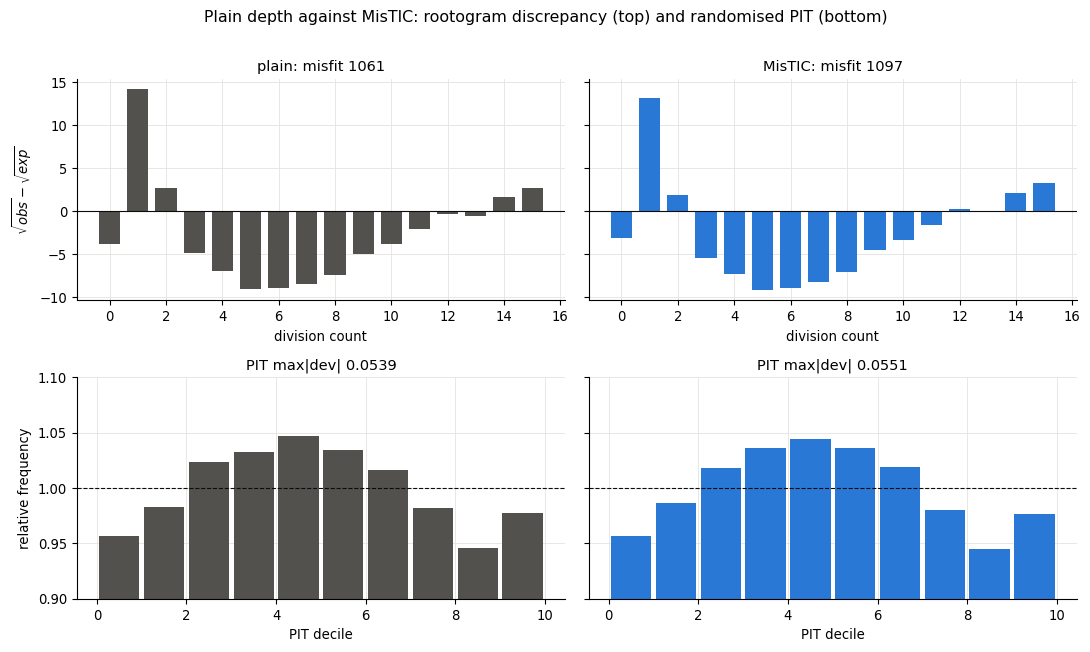

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4), sharey="row")
KS = np.arange(16)
for j, t in enumerate(TECH):
    f = tech_fit[t]
    obs, exp_ = nbb.rootogram(y, f["mu"], f["alpha"])
    ax = axes[0, j]
    ax.bar(KS, (np.sqrt(obs) - np.sqrt(exp_))[:16], width=0.75, color=COL["real"] if t == "MisTIC" else COL["base"])
    ax.axhline(0, color=INK, lw=0.8)
    ax.set_title(f"{t}: misfit {tech_tab.loc[t, 'rootogram misfit']:.0f}")
    ax.set_xlabel("division count")
    u = nbb.pit(y, f["mu"], f["alpha"])
    ax = axes[1, j]
    ax.bar(np.arange(10) + 0.5, np.histogram(u, 10, (0, 1))[0] / (n / 10), width=0.9,
           color=COL["real"] if t == "MisTIC" else COL["base"])
    ax.axhline(1, color=INK, lw=0.8, ls="--"); ax.set_ylim(0.9, 1.1)
    ax.set_xlabel("PIT decile"); ax.set_title(f"PIT max|dev| {tech_tab.loc[t, 'PIT max|dev|']:.4f}")
axes[0, 0].set_ylabel(r"$\sqrt{obs}-\sqrt{exp}$"); axes[1, 0].set_ylabel("relative frequency")
fig.suptitle("Plain depth against MisTIC: rootogram discrepancy (top) and randomised PIT (bottom)", y=1.01)
fig.tight_layout(); savefig(fig, "technical_calibration")

# do the state effects depend on the technical terms?
eff_t = {t: pd.concat({"own": nbb.state_effects(tech_fit[t], basis, "a"),
                       "nbr": nbb.state_effects(tech_fit[t], basis, "c")}) for t in TECH}
st = eff_t["plain"].join(eff_t["MisTIC"], lsuffix="_plain", rsuffix="_mistic")
st["shift_in_se"] = (st["estimate_mistic"] - st["estimate_plain"]) / st["se_mistic"]
print(f"own + neighbour effects, plain vs MisTIC: Pearson r = "
      f"{np.corrcoef(st['estimate_plain'], st['estimate_mistic'])[0, 1]:.4f}; largest shifts (SE):")
st.reindex(st["shift_in_se"].abs().sort_values(ascending=False).index)[
    ["estimate_plain", "estimate_mistic", "shift_in_se"]].head(8).round(3)

### Reading §1

**MisTIC is better out of sample on every fold.**
- Held out, it gains 3,290 log-likelihood over the five folds (+545 to +758 per fold),
  for one extra parameter, $\theta_m$ = 1.98.
- In sample it gains 3,236. The dispersion falls from 0.752 to 0.714.
- Residual Moran's I falls from 0.075 to 0.060.
- The count shape does not improve: rootogram misfit is 1,061 (plain) against 1,097
  (MisTIC), and the PIT is about the same (0.054 against 0.055).
- The mixture shows the same pattern (`mixture_model.ipynb` §2): +3,920 held out,
  calibration unchanged.

**What MisTIC changes in the effects.** The two sets correlate at 0.993, but:
- The own-state effects sharpen. Own T-cells go from 0.355 to 0.421 (+6.6 SE), CAFs
  from −0.52 to −0.60 (−5.0 SE), and B-cells from 0.350 to 0.415 (+4.3 SE).
- The regional neighbourhood effects shrink. Regional Cancer Epithelial halves (0.154
  to 0.082), and regional T-cells fall from 0.108 to 0.051.

That is what modelled spillover should do. Cycle-gene transcripts misassigned from
proliferating neighbours were being credited to the neighbourhood; with
$\theta_m m$ in the mean they are not.

**Decision (user, 2026-10-13): MisTIC is the production technical model.** The rest
of this notebook uses it.

## 2. Choosing the baseline: depth and dispersion

Two specification choices from the old notebook are retested here.

**Depth: is the offset right?** With $\theta$ fixed at 1, $\log N$ is an offset
and the model is a *rate* model: state effects read "per transcript captured".
That is the production choice. The old notebook's §21 found
$\theta \approx 0.70$, with depth measured as total counts. The SpaNorm table
gave $\theta = -0.25$, a symptom of its artefact: the depth signal was split
between $\log N$ and the depth-laden state scores. Here the library size is $\tilde N$.
It excludes the Tirosh genes and the blocklist, and down-weights transcripts
that MisTIC judges misassigned. The mean also carries $\theta_m m_i$ (§1).

The offset is tested four ways, because a single free exponent only asks
whether the *average* slope is 1:
1. a free exponent $\theta$;
2. the offset plus a natural spline in $\log N$ (5 df), which lets the depth
   response bend anywhere in its range;
3. the offset plus per-cell-type slope deviations,
   $(\phi_i^\top t)(\log N_i - \overline{\log N})$ (8 df);
4. observed over expected counts by decile of depth.

**Dispersion: NB-c (constant) or NB-d (state-dependent)?** The alternative is
$\log\alpha_i = \gamma_0 + \phi_i^\top\gamma$, the old §24 submodel and the
division comparison's NB-d. Both variants are fit by joint penalised maximum
likelihood. The constant-$\alpha$ row is therefore an honest baseline, and the
old notebook's moment-estimator comparison does not arise.

The four depth-by-dispersion combinations, plus the two extra depth models,
are all fit on all 561,897 cells. The criteria, in order:
1. calibration: rootogram misfit and PIT;
2. residual Moran's I;
3. likelihood per parameter.

In [4]:
GRID = [(th, disp) for th in ("offset", "free") for disp in ("const", "state")]
tune = {key: nbb.cached(f"tune_{key[0]}_{key[1]}",
                        lambda key=key: nbb.fit(D, theta=key[0], dispersion=key[1], say=print, **PEN))
        for key in GRID}
depth_fits = {th: nbb.cached(f"tune_{th}_const", lambda th=th: nbb.fit(
                  D, theta=th, dispersion="const", init=tune[("offset", "const")]["params"],
                  say=print, **PEN))
              for th in ("spline", "by_type")}
roots = {key: nbb.rootogram(y, f["mu"], f["alpha"]) for key, f in tune.items()}

rows = []
for key, f in tune.items():
    r = nbb.summarise(f, y, T_all)
    r["theta_se"] = float(np.sqrt(nbb.estimate(f, "theta")[1][0, 0])) if key[0] == "free" else np.nan
    rows.append({"depth": key[0], "dispersion": key[1], **r})
for th, f in depth_fits.items():
    rows.append({"depth": th, "dispersion": "const", **nbb.summarise(f, y, T_all), "theta_se": np.nan})
tune_tab = pd.DataFrame(rows).set_index(["depth", "dispersion"])
tune_tab.to_csv(OUT / "tuning.csv")
tune_tab[["k", "loglik", "theta", "theta_se", "alpha", "rootogram_misfit", "worst_bin",
          "worst_count", "pit_maxdev", "resid_moran", "converged", "minutes"]]

k       loglik   theta  theta_se   alpha  rootogram_misfit  worst_bin  worst_count  pit_maxdev  resid_moran  converged  minutes
depth   dispersion                                                                                                                                   
offset  const       144 -593607.9760  1.0000       NaN  0.7139         1096.8746    13.7102           30      0.0551       0.0603       True   1.4505
        state       152 -593444.2879  1.0000       NaN  0.7019         1042.5329    13.4425           30      0.0561       0.0602       True   1.7597
free    const       145 -593225.2185  1.0966    0.0036  0.7035         1057.0179    15.7214            1      0.0495       0.0646       True   1.5722
        state       153 -593083.5788  1.0941    0.0036  0.6926         1009.3935    15.0305            1      0.0503       0.0643       True   1.7044
spline  const       149 -592625.3951  1.0000       NaN  0.6965          649.5997    13.1461            1      0.0441       0.0621       True   1.3706
by_type const       152 -592914.9800  1.0000       NaN  0.7026          934.2116    12.6113            1      0.0485       0.0629       True   0.6913

In [5]:
ALL = {**tune, ("spline", "const"): depth_fits["spline"], ("by_type", "const"): depth_fits["by_type"]}
def lr(a, b, df_):
    s = 2 * (ALL[b]["loglik"] - ALL[a]["loglik"])
    return dict(LR=s, df=df_, dAIC=2 * df_ - s, dBIC=df_ * np.log(n) - s)

pd.DataFrame({
    "depth spline vs offset":               lr(("offset", "const"), ("spline", "const"), D["Nbasis"].shape[1]),
    "per-type depth slopes vs offset":      lr(("offset", "const"), ("by_type", "const"), D["own"].shape[1]),
    "free theta vs offset, constant alpha": lr(("offset", "const"), ("free", "const"), 1),
    "free theta vs offset, state alpha":    lr(("offset", "state"), ("free", "state"), 1),
    "state alpha vs constant, offset":      lr(("offset", "const"), ("offset", "state"), 8),
    "state alpha vs constant, free theta":  lr(("free", "const"), ("free", "state"), 8),
}).T

,LR,df,dAIC,dBIC
depth spline vs offset,1965.1618,5.0,-1955.1618,-1898.9664
per-type depth slopes vs offset,1385.9920,8.0,-1369.9920,-1280.0794
"free theta vs offset, constant alpha",765.5150,1.0,-763.5150,-752.2759
"free theta vs offset, state alpha",721.4182,1.0,-719.4182,-708.1791
"state alpha vs constant, offset",327.3762,8.0,-311.3762,-221.4636
"state alpha vs constant, free theta",283.2793,8.0,-267.2793,-177.3668


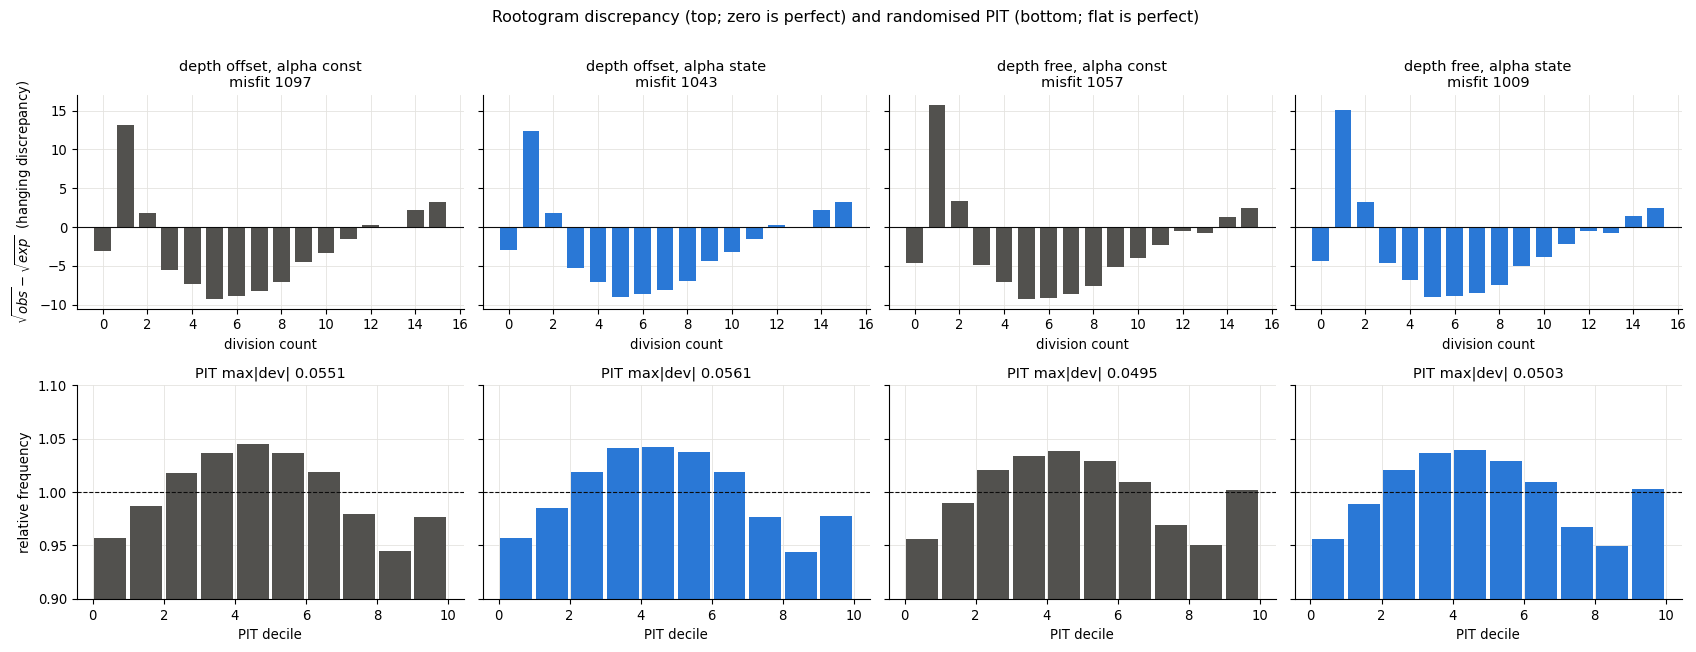

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(17, 6.4), sharey="row")
KS = np.arange(16)
for j, key in enumerate(GRID):
    obs, exp_ = roots[key]
    d = np.sqrt(obs) - np.sqrt(exp_)
    ax = axes[0, j]
    ax.bar(KS, d[:16], width=0.75, color=COL["real"] if key[1] == "state" else COL["base"])
    ax.axhline(0, color=INK, lw=0.8)
    ax.set_title(f"depth {key[0]}, alpha {key[1]}\nmisfit {tune_tab.loc[key, 'rootogram_misfit']:.0f}")
    ax.set_xlabel("division count")
    u = nbb.pit(y, tune[key]["mu"], tune[key]["alpha"])
    h = np.histogram(u, 10, (0, 1))[0] / (n / 10)
    ax = axes[1, j]
    ax.bar(np.arange(10) + 0.5, h, width=0.9, color=COL["real"] if key[1] == "state" else COL["base"])
    ax.axhline(1, color=INK, lw=0.8, ls="--"); ax.set_ylim(0.9, 1.1)
    ax.set_xlabel("PIT decile"); ax.set_title(f"PIT max|dev| {tune_tab.loc[key, 'pit_maxdev']:.4f}")
axes[0, 0].set_ylabel(r"$\sqrt{obs}-\sqrt{exp}$  (hanging discrepancy)")
axes[1, 0].set_ylabel("relative frequency")
fig.suptitle("Rootogram discrepancy (top; zero is perfect) and randomised PIT (bottom; flat is perfect)", y=1.01)
fig.tight_layout(); savefig(fig, "tuning_calibration")

In [7]:
# Do the state coefficients depend on the depth specification? (old §21's stability check)
eff = {key: pd.concat({"own": nbb.state_effects(tune[key], basis, "a"),
                       "nbr": nbb.state_effects(tune[key], basis, "c")}) for key in GRID}
a_, b_ = eff[("offset", "const")], eff[("free", "const")]
stab = a_.join(b_, lsuffix="_offset", rsuffix="_free")
stab["shift_in_se"] = (stab["estimate_free"] - stab["estimate_offset"]) / stab["se_offset"]
print(f"own + neighbour effects, offset vs free depth: Pearson r = "
      f"{np.corrcoef(stab['estimate_offset'], stab['estimate_free'])[0, 1]:.5f}, "
      f"largest shift {stab['shift_in_se'].abs().max():.2f} SE")
stab[["estimate_offset", "estimate_free", "z_offset", "z_free", "shift_in_se"]].round(3)

own + neighbour effects, offset vs free depth: Pearson r = 0.99179, largest shift 4.97 SE


estimate_offset  estimate_free  z_offset  z_free  shift_in_se
own Endothelial                          -0.303         -0.323   -22.467 -23.546       -1.502
    CAFs                                 -0.600         -0.625   -39.631 -40.862       -1.605
    PVL                                  -0.137         -0.134    -7.672  -7.347        0.211
    B-cells                               0.415          0.458    27.300  29.532        2.822
    T-cells                               0.421          0.472    41.372  45.095        4.969
    Myeloid                              -0.249         -0.248   -21.811 -21.524        0.159
    Normal Epithelial                    -0.178         -0.225   -12.545 -15.543       -3.375
    Plasmablasts                          0.091          0.120     4.676   6.093        1.509
    Cancer Epithelial                     0.541          0.504    42.214  38.741       -2.821
nbr contact:Endothelial                  -0.157         -0.152    -7.726  -7.313        0.272
    contact:CAFs                         -0.093         -0.092    -4.711  -4.642        0.050
    contact:PVL                          -0.160         -0.165    -5.759  -5.838       -0.181
    contact:B-cells                      -0.034         -0.012    -1.410  -0.482        0.923
    contact:T-cells                       0.097          0.110     6.016   6.782        0.831
    contact:Myeloid                      -0.138         -0.137    -8.012  -7.892        0.071
    contact:Normal Epithelial            -0.028         -0.055    -1.126  -2.173       -1.069
    contact:Plasmablasts                  0.049          0.068     1.477   2.034        0.569
    contact:Cancer Epithelial             0.465          0.435    23.072  21.333       -1.518
    regional:Endothelial                 -0.593         -0.492   -11.162  -9.144        1.892
    regional:CAFs                        -0.042         -0.023    -1.001  -0.543        0.455
    regional:PVL                          0.338          0.343     5.027   5.012        0.069
    regional:B-cells                     -0.073         -0.055    -1.468  -1.092        0.367
    regional:T-cells                      0.051         -0.039     1.657  -1.229       -2.903
    regional:Myeloid                     -0.011         -0.026    -0.243  -0.583       -0.344
    regional:Normal Epithelial           -0.351         -0.339    -4.684  -4.496        0.155
    regional:Plasmablasts                 0.598          0.636     6.908   7.297        0.437
    regional:Cancer Epithelial            0.082         -0.006     1.895  -0.128       -2.023

### The shape of the depth response

Three views of the offset assumption, all on constant-$\alpha$ fits:
- **left:** the spline model's deviation from the offset, with pointwise 95%
  bands, over the central 99% of $\log N$. The free-exponent line is drawn for
  comparison. A correct offset is flat at zero.
- **middle:** the depth exponent implied for each cell type by the per-type
  slope model, $1 + \bar\phi_k^\top t$, where $\bar\phi_k$ is the mean
  projected state of cells argmax-typed as $k$.
- **right:** observed over expected division counts in each decile of $\log N$
  under the offset model, with ±2 SE. A correct offset sits at 1 in every decile.

per-cell depth exponent under the per-type model: 5-95% range 0.752-1.235
largest spline deviation from the offset over the central 99% of log N: 0.493 on the log scale (63.8%)


,depth exponent,se
CAFs,0.843,0.011
Endothelial,0.885,0.009
Normal Epithelial,0.911,0.006
Myeloid,0.926,0.009
PVL,0.946,0.010
Plasmablasts,0.970,0.008
B-cells,1.048,0.010
Cancer Epithelial,1.083,0.004
T-cells,1.167,0.008


,median N,O/E offset,se,O/E spline
0,13.0,1.0522,0.0136,0.9899
1,20.0,1.0091,0.0111,0.9819
2,29.0,0.9699,0.0096,0.9792
3,39.0,0.9657,0.0085,1.0011
4,51.0,0.9532,0.0077,0.9945
5,65.0,0.9290,0.0071,0.9643
6,86.0,0.9522,0.0065,0.9913
7,125.0,0.9695,0.0058,1.0254
8,206.0,0.9753,0.0049,1.0226
9,385.0,1.1542,0.0044,1.0248


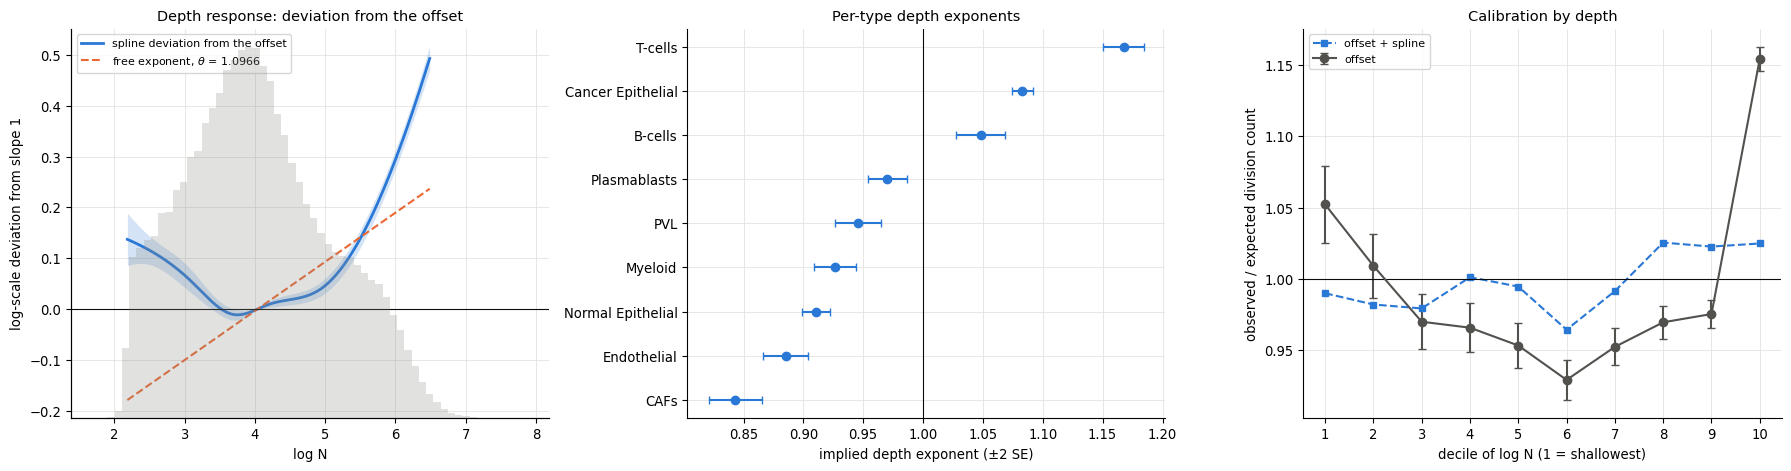

In [8]:
from tissue_dynamics.mixture.basis import _Spline
fo, fsp, fbt, ffr = tune[("offset", "const")], depth_fits["spline"], depth_fits["by_type"], tune[("free", "const")]
Nsp = _Spline(D["logN"], nbb.DEPTH_SPLINE_DF)          # the frozen basis load_design used
qN = np.quantile(D["logN"], np.linspace(0.005, 0.995, 200))
mN = D["logN"].mean()
v, Cv = nbb.estimate(fsp, "tN")
Bq = Nsp(qN) - Nsp(np.array([mN]))                      # deviation, pinned to 0 at mean log N
dev, dev_se = Bq @ v, np.sqrt(np.einsum("ij,jk,ik->i", Bq, Cv, Bq))
th_free = float(ffr["params"]["theta"])

vt, Ct = nbb.estimate(fbt, "tT")
slopes = pd.DataFrame({t: {"depth exponent": 1 + D["own"][ctype == t].mean(0) @ vt,
                           "se": float(np.sqrt(D["own"][ctype == t].mean(0) @ Ct @ D["own"][ctype == t].mean(0)))}
                       for t in TYPES}).T.sort_values("depth exponent")
cell_slope = 1 + D["own"] @ vt
print(f"per-cell depth exponent under the per-type model: 5-95% range "
      f"{np.percentile(cell_slope, 5):.3f}-{np.percentile(cell_slope, 95):.3f}")

dec = pd.qcut(D["logN"], 10, labels=False)
def oe(f):
    mu, a = f["mu"], f["alpha"]
    var = mu + (a if np.isscalar(a) else a) * mu ** 2
    o = np.bincount(dec, weights=y); e = np.bincount(dec, weights=mu); v_ = np.bincount(dec, weights=var)
    return o / e, np.sqrt(v_) / e
oe_off, oe_off_se = oe(fo); oe_sp, _ = oe(fsp)
dec_tab = pd.DataFrame({"median N": [np.median(df["N"].to_numpy()[dec == k]) for k in range(10)],
                        "O/E offset": oe_off, "se": oe_off_se, "O/E spline": oe_sp})
print(f"largest spline deviation from the offset over the central 99% of log N: "
      f"{np.max(np.abs(dev)):.3f} on the log scale ({100 * (np.exp(np.max(np.abs(dev))) - 1):.1f}%)")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
ax.fill_between(qN, dev - 2 * dev_se, dev + 2 * dev_se, color=COL["real"], alpha=0.2, lw=0)
ax.plot(qN, dev, color=COL["real"], lw=2, label="spline deviation from the offset")
ax.plot(qN, (th_free - 1) * (qN - mN), "--", color=COL["decoy"], label=rf"free exponent, $\theta$ = {th_free:.4f}")
ax.axhline(0, color=INK, lw=0.8)
ax.set_xlabel("log N"); ax.set_ylabel("log-scale deviation from slope 1"); ax.legend(fontsize=8)
ax.set_title("Depth response: deviation from the offset")
ax2 = ax.twinx(); ax2.hist(D["logN"], bins=60, color=MUTED, alpha=0.25); ax2.set_yticks([]); ax2.grid(False)
ax = axes[1]
ax.errorbar(slopes["depth exponent"], np.arange(len(slopes)), xerr=2 * slopes["se"], fmt="o",
            color=COL["real"], capsize=3)
ax.axvline(1, color=INK, lw=0.8); ax.set_yticks(np.arange(len(slopes))); ax.set_yticklabels(slopes.index)
ax.set_xlabel("implied depth exponent (±2 SE)"); ax.set_title("Per-type depth exponents")
ax = axes[2]
ax.errorbar(np.arange(10) + 1, oe_off, yerr=2 * oe_off_se, fmt="o-", color=COL["base"], capsize=3, label="offset")
ax.plot(np.arange(10) + 1, oe_sp, "s--", color=COL["real"], ms=4, label="offset + spline")
ax.axhline(1, color=INK, lw=0.8); ax.set_xticks(np.arange(10) + 1)
ax.set_xlabel("decile of log N (1 = shallowest)"); ax.set_ylabel("observed / expected division count")
ax.set_title("Calibration by depth"); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "depth_offset_tests")
display(slopes.round(3)); dec_tab.round(4)

In [9]:
# Dispersion submodel: which cell types are over- or under-dispersed?
th_d = "offset"
fs, fc = tune[(th_d, "state")], tune[(th_d, "const")]
g = nbb.state_effects(fs, basis, "gamma")
g["exp(gamma)"] = np.exp(g["estimate"])
rc = nbb.rootogram(y, fc["mu"], fc["alpha"], groups=ctype)
rs = nbb.rootogram(y, fs["mu"], fs["alpha"], groups=ctype)
per = pd.DataFrame({t: {"cells": int((ctype == t).sum()),
                        "median alpha_i": float(np.median(fs["alpha"][ctype == t])),
                        "misfit, constant": nbb.misfit(*rc[t]), "misfit, state": nbb.misfit(*rs[t])}
                    for t in TYPES}).T
per["change %"] = 100 * (per["misfit, state"] / per["misfit, constant"] - 1)
print(f"constant alpha {fc['alpha']:.4f}; state alpha_i median {np.median(fs['alpha']):.4f}, "
      f"IQR {np.percentile(fs['alpha'], 25):.4f}-{np.percentile(fs['alpha'], 75):.4f}")
g[["exp(gamma)", "estimate", "se", "z"]].join(per).sort_values("exp(gamma)").round(3)

constant alpha 0.7139; state alpha_i median 0.7019, IQR 0.6423-0.7580


,exp(gamma),estimate,se,z,cells,median alpha_i,"misfit, constant","misfit, state",change %
Normal Epithelial,0.728,-0.317,0.036,-8.821,53149.0,0.629,150.325,129.286,-13.996
CAFs,0.778,-0.251,0.041,-6.181,52506.0,0.562,58.459,37.444,-35.948
Plasmablasts,0.902,-0.104,0.046,-2.251,42228.0,0.637,62.317,58.998,-5.325
PVL,1.010,0.010,0.046,0.209,40175.0,0.698,41.721,39.768,-4.680
B-cells,1.019,0.019,0.035,0.544,57825.0,0.682,105.865,99.506,-6.007
T-cells,1.066,0.064,0.022,2.893,89213.0,0.717,247.373,245.092,-0.922
Endothelial,1.112,0.106,0.031,3.426,47810.0,0.737,59.308,62.270,4.993
Myeloid,1.198,0.181,0.028,6.395,68186.0,0.764,78.713,83.780,6.437
Cancer Epithelial,1.340,0.293,0.023,12.993,110805.0,0.743,841.784,837.917,-0.459


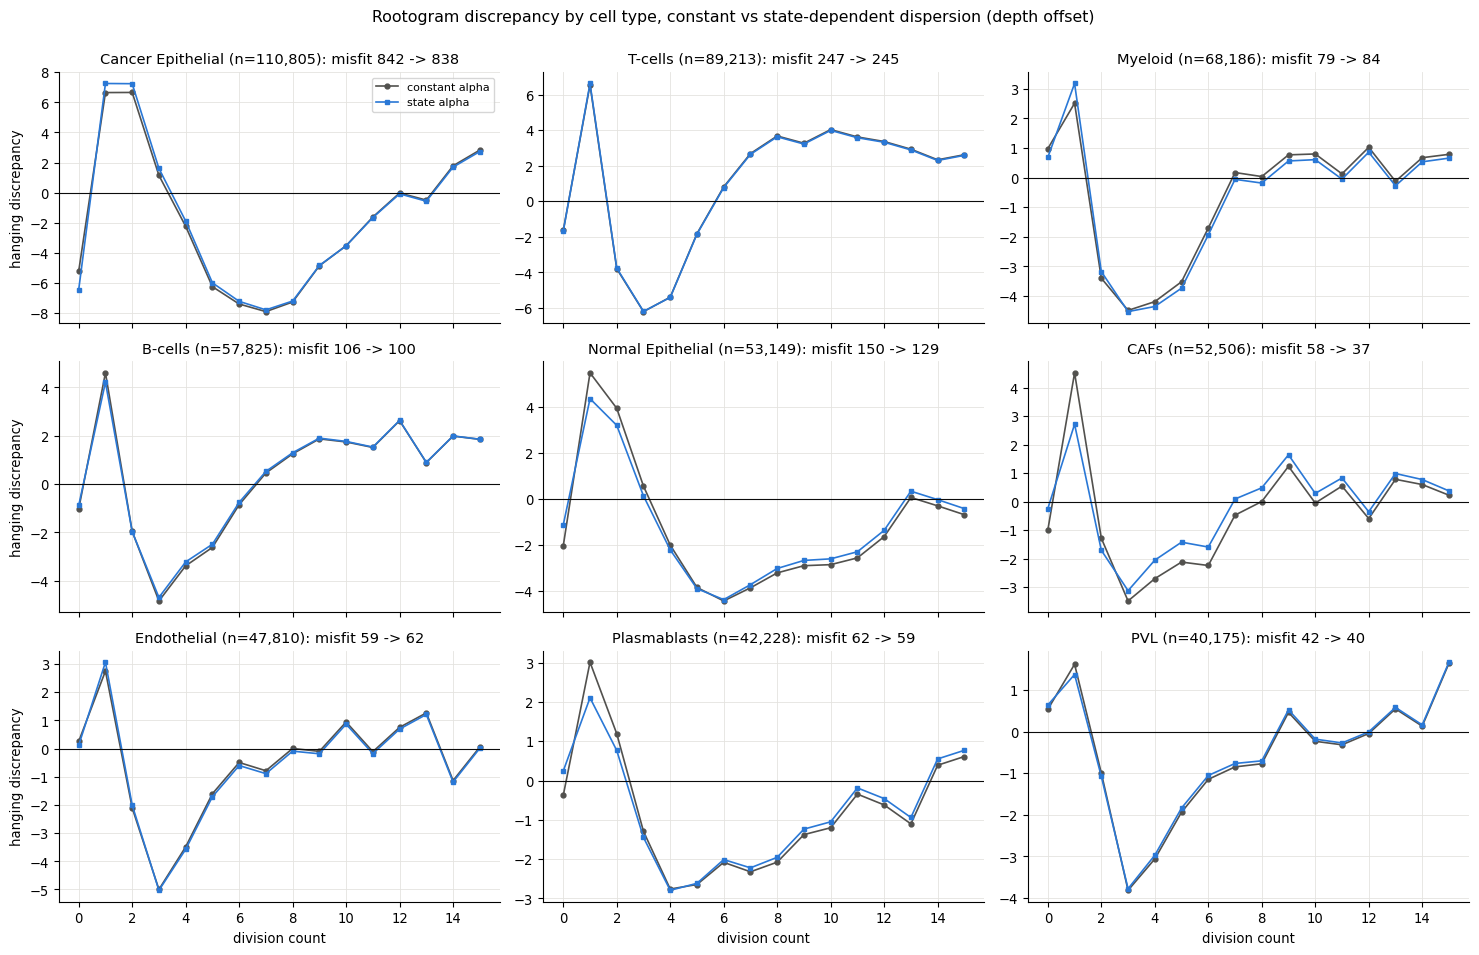

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(15, 9.5), sharex=True)
for ax, t in zip(axes.ravel(), sorted(TYPES, key=lambda t: -(ctype == t).sum())):
    for lab, R, c, m in (("constant alpha", rc, COL["base"], "o"), ("state alpha", rs, COL["real"], "s")):
        o, e = R[t]
        ax.plot(KS, (np.sqrt(o) - np.sqrt(e))[:16], m + "-", ms=3.5, lw=1.2, color=c, label=lab)
    ax.axhline(0, color=INK, lw=0.8)
    ax.set_title(f"{t} (n={(ctype == t).sum():,}): misfit {per.loc[t, 'misfit, constant']:.0f} "
                 f"-> {per.loc[t, 'misfit, state']:.0f}")
axes[0, 0].legend(fontsize=8)
for ax in axes[-1]: ax.set_xlabel("division count")
for ax in axes[:, 0]: ax.set_ylabel("hanging discrepancy")
fig.suptitle("Rootogram discrepancy by cell type, constant vs state-dependent dispersion (depth offset)", y=1.0)
fig.tight_layout(); savefig(fig, "tuning_dispersion_by_type")

### NB-c against NB-d, head to head

The dispersion choice on its own: both with the MisTIC terms (justified in §1) and
the depth offset, differing only in $\log\alpha$ — one constant (NB-c) or
$\gamma_0 + \phi_i^\top\gamma$ on the own state (NB-d, 8 extra parameters). Held out on
the same five spatial folds as §1; NB-c's folds are §1's MisTIC folds.

In [11]:
disp_fit = {"NB-c": tune[("offset", "const")], "NB-d": tune[("offset", "state")]}
cv_disp = {"NB-c": cv_tech["MisTIC"],
           "NB-d": spatial_cv("disp_state", D, disp_fit["NB-d"], theta="offset", dispersion="state")}
disp_tab = compare(disp_fit, cv_disp, ref="NB-c")
lr_d = 2 * (disp_fit["NB-d"]["loglik"] - disp_fit["NB-c"]["loglik"])
print(f"LR (NB-d vs NB-c) {lr_d:,.1f} on 8 df; dAIC {16 - lr_d:+,.1f}; dBIC {8 * np.log(n) - lr_d:+,.1f}")
disp_tab.to_csv(OUT / "dispersion_nbc_vs_nbd.csv")
disp_tab

LR (NB-d vs NB-c) 327.4 on 8 df; dAIC -311.4; dBIC -221.5


,parameters,loglik,AIC,rootogram misfit,PIT max|dev|,residual Moran's I,held-out loglik,held-out gain vs NB-c,per-fold gains,folds better,all CV fits converged
NB-c,144,-593607.976,1187503.9521,1096.8746,0.0551,0.0603,-593809.3758,0.0,+0 / +0 / +0 / +0 / +0,NaN,True
NB-d,152,-593444.2879,1187192.5759,1042.5329,0.0561,0.0602,-593664.0056,145.3702,+42 / +37 / +32 / -5 / +40,4,True


**NB-d is better, by a small margin.**
- In sample, the likelihood ratio is 327 on 8 df (ΔAIC −311, ΔBIC −222).
- Held out, NB-d gains 145 over the five folds and is better on four of them
  (+32 to +42, and −5 on fold 3).
- Rootogram misfit falls 5% (1,097 to 1,043). The PIT is essentially unchanged
  (0.055 against 0.056), and so is residual Moran's I (0.060).

The gain is real but small: about 30 log-likelihood per fold for 8 parameters. It
sits mostly in CAFs and Normal Epithelial (below). NB-c stays the baseline for §3–5
(its decision is unchanged), and NB-d is the better single NB as a model for the
counts. The division comparison and `mixture_model.ipynb` §5 use NB-d for that reason.

### Reading §2

**Depth now departs clearly from proportionality.**
- The free exponent is $\hat\theta = 1.097$ (SE 0.004): LR 766 on 1 df, or 721
  with state-dependent dispersion.
- Freeing it moves the state effects, by up to 5.0 SE (correlation 0.992 between
  the two sets). The largest moves are:
  - own T-cells, +4.97 SE;
  - own Normal Epithelial, −3.4;
  - own B-cells and Cancer Epithelial, ±2.8;
  - regional T-cells, −2.9.

**The departures across the depth range and by cell type are clear.**
- **Spline.** A spline deviation from the offset gains 983 units (LR 1,965 on 5
  df) and cuts rootogram misfit by 41% (1,097 to 650). Under the offset,
  observed/expected by depth decile is:
  - 1.05 in the shallowest (median N = 13);
  - 0.93–0.98 in the middle;
  - 1.15 in the deepest (median N = 385).

  The spline flattens that to 0.96–1.03.
- **Per-type slopes.** They gain 693 units (LR 1,386 on 8 df), and rootogram
  misfit improves by 15%. Implied exponents run from 0.84 (CAFs) to 1.17
  (T-cells).

**Technical or biological?** The per-type exponents broadly track the types'
cycling fractions: lowest in CAFs and Endothelial, highest in T-cells and Cancer
Epithelial. The deepest decile carries the largest excess. That is what you would
expect if cycling cells carry more RNA. A free or flexible depth term would then
absorb division signal, which is why the offset was chosen.

**Decision (user, 2026-10-13): the offset stays in production, and the
free-$\theta$ fit is reported beside it.** The `theta_bracket` job fitted the
mixture with $\theta$ pinned and free (Configurations F and V;
`outputs/theta_bracket/report.md`):
- Free, $\hat\theta$ = 1.119, close to this baseline's 1.097.
- The priority-pair neighbourhood effects hold: 15 of 16 stay inside the pinned
  fit's 95% intervals, with a median shift of 0.9 SE.
- The cycling level does not. The fraction rises from 0.098 to 0.133: by
  ×1.5–1.7 in the immune and stromal types, and by ×1.11 in Cancer Epithelial,
  the deepest cells. Cycling levels and between-type contrasts are therefore
  reported as a range.

**State-dependent dispersion helps the marginal fit, not calibration.**
- LR 327 on 8 df; rootogram misfit falls 5% (1,097 to 1,043).
- The gain sits mostly in CAFs (−36%), Normal Epithelial (−14%), B-cells (−6%)
  and Plasmablasts (−5%). Myeloid (+6%) and Endothelial (+5%) get slightly worse.
- The PIT worsens slightly (0.055 to 0.056), and residual Moran's I is unchanged
  (0.060).
- Over-dispersed types: Cancer Epithelial ($e^\gamma$ = 1.34), Myeloid (1.20)
  and Endothelial (1.11). Under-dispersed: Normal Epithelial (0.73) and CAFs
  (0.78).

**Every specification keeps the same shape defect,** which the mixture exists to
fix. Against the expected counts there are:
- too few zeros;
- too many 1s;
- too few 3s to 11s, most at 5–6;
- too many counts of 14 and above.

**Baseline for §3–5: offset, constant $\alpha$, no oxygen.** The reasoning and
the decision log are in the [specification decisions document](https://claude.ai/code/artifact/70c686de-ba2d-4b2d-8d17-f29b5e2c2077).

In [12]:
BASE = dict(theta="offset", dispersion="const")    # the decision above
base_fit = tune[(BASE["theta"], BASE["dispersion"])]
print("baseline:", BASE, "| no oxygen term |", f"loglik {base_fit['loglik']:,.1f} | "
      f"alpha {base_fit['alpha']:.4f} | {nbb.n_params(base_fit['params'])} parameters")

baseline: {'theta': 'offset', 'dispersion': 'const'} | no oxygen term | loglik -593,608.0 | alpha 0.7139 | 144 parameters


## 3. The oxygen field

**Status: dropped.** On the evidence below, $\psi\,u$ was removed from every
model on 2026-10-06 (`model.oxygen: false`). The baseline has no oxygen term,
and this section adds it back only to test it.

The field is a steady-state screened-diffusion solve over the rasterised
section (`tissue_dynamics.oxygen`):

$$\nabla^2 u = \kappa(x)\,u, \qquad -\nabla u\cdot\hat n = \beta\,\Phi(x)\,(1-u).$$

$\Phi$ marks the endothelial source cells. Consumption
$\kappa = (1/L_0^2)(n/n_0)$ rises with local density, so $L_0$ is the screening
length at reference density: roughly how far oxygen reaches from a vessel. $u$
is scale-free relative oxygenation in $[0,1]$, not pO₂.

**What changed.** The source is now the log1p Endothelial score of typed cells
($N \ge 10$). The top 2.6% after z-scoring are sources, at grid pitch 5 µm,
$L_0 = 100$ µm and $\beta = 1$. The old field came from the SpaNorm minor
table, whose endothelial columns tracked depth. It did not mark vessels: AUROC
0.515 for marker-identified endothelium. Every oxygen result in the old
notebook therefore needs redoing, including:
- the ~13× margin over the rotated decoy;
- the $L_0$ optimum at 100–200 µm;
- the HIF failure.

One deviation to keep in mind: the major-table Endothelial column includes
lymphatic endothelium, which carries no oxygenated blood. The old source
excluded it.

The plan:
1. Rebuild the field and check that it reproduces the table column.
2. Test that its source marks vessels.
3. Rerun the HIF-marker gate.
4. Test whether $u$ explains division beyond cell state, against three decoys,
   at every $L_0$ in the sweep.

In [13]:
cells = nbb.cached("all_cells", lambda: nbb.all_cells(cfg))
src_xy, src_score = nbb.oxygen_source(cells, cfg)
txy = df[["x", "y"]].to_numpy(float)
L0S = (50.0, 100.0, 200.0, 400.0, 800.0)

f100 = nbb.cached("field_L100", lambda: nbb.field_samples(txy, src_xy, src_score, 100.0, cfg,
                                                          keep_raster=True))
print(f"{len(cells):,} cells with PhiSpace scores, {cells['typed'].sum():,} typed; "
      f"{(src_score > 0).sum():,} sources ({100 * (src_score > 0).mean():.2f}% of typed cells)")
print(f"reproduces the table's oxygen column: max |difference| = "
      f"{np.nanmax(np.abs(f100['u'] - df['oxygen'].to_numpy())):.1e}")

# zoom window: the 2.5 mm square (500 px) where u varies most, among windows >= 95% tissue
R = f100["raster"]; blk, wb = 100, 5
best, WIN = -1.0, None
for a in range(R.shape[0] // blk - wb + 1):
    for b in range(R.shape[1] // blk - wb + 1):
        w = R[a * blk:(a + wb) * blk, b * blk:(b + wb) * blk]
        if np.isfinite(w).mean() >= 0.95 and np.nanstd(w) > best:
            best, WIN = float(np.nanstd(w)), ((a * blk, (a + wb) * blk), (b * blk, (b + wb) * blk))

fields = {}
for L0 in L0S:
    F = f100 if L0 == 100.0 else nbb.cached(f"field_L{int(L0)}", lambda L0=L0: nbb.field_samples(
        txy, src_xy, src_score, L0, cfg, keep_raster=True))
    fields[L0] = dict(F, window=F["raster"][WIN[0][0]:WIN[0][1], WIN[1][0]:WIN[1][1]])
xa, sa = nbb.oxygen_source(cells, cfg, consumers="all")
f_all = nbb.cached("field_L100_allconsumers", lambda: nbb.field_samples(txy, xa, sa, 100.0, cfg))

rows = []
for L0, F in fields.items():
    u, d = F["u"], F["diagnostics"]; ok = np.isfinite(u)
    rows.append({"L0": L0, "unknowns": d["n_unknowns"], "rel_residual": d["rel_residual"],
                 "mean u": np.nanmean(u), "sd u": np.nanstd(u),
                 "corr(u, log N)": np.corrcoef(u[ok], logN[ok])[0, 1],
                 "corr(u, log density)": np.corrcoef(u[ok], np.log(df["density"].to_numpy())[ok])[0, 1],
                 "solve min": F["minutes"]})
field_tab = pd.DataFrame(rows).set_index("L0")
ok = np.isfinite(f_all["u"]) & np.isfinite(f100["u"])
print(f"variant where shallow cells also consume oxygen: corr with production {np.corrcoef(f_all['u'][ok], f100['u'][ok])[0, 1]:.4f}, "
      f"mean u {np.nanmean(f_all['u']):.3f} vs {np.nanmean(f100['u']):.3f}")
field_tab

683,218 cells with PhiSpace scores, 564,004 typed; 14,665 sources (2.60% of typed cells)
reproduces the table's oxygen column: max |difference| = 4.0e-09


variant where shallow cells also consume oxygen: corr with production 0.9754, mean u 0.310 vs 0.333


,unknowns,rel_residual,mean u,sd u,"corr(u, log N)","corr(u, log density)",solve min
L0,,,,,,,
50.0,4501235,8.6654e-11,0.1312,0.1247,-0.0840,-0.2222,0.2853
100.0,4501235,9.6069e-11,0.3335,0.1671,-0.0966,-0.2700,0.3466
200.0,4501235,7.9749e-11,0.6314,0.1493,-0.0874,-0.2609,0.3455
400.0,4501235,7.1267e-11,0.8598,0.0900,-0.0601,-0.1818,0.3464
800.0,4501235,9.2052e-11,0.9576,0.0480,-0.0235,-0.0567,0.3787


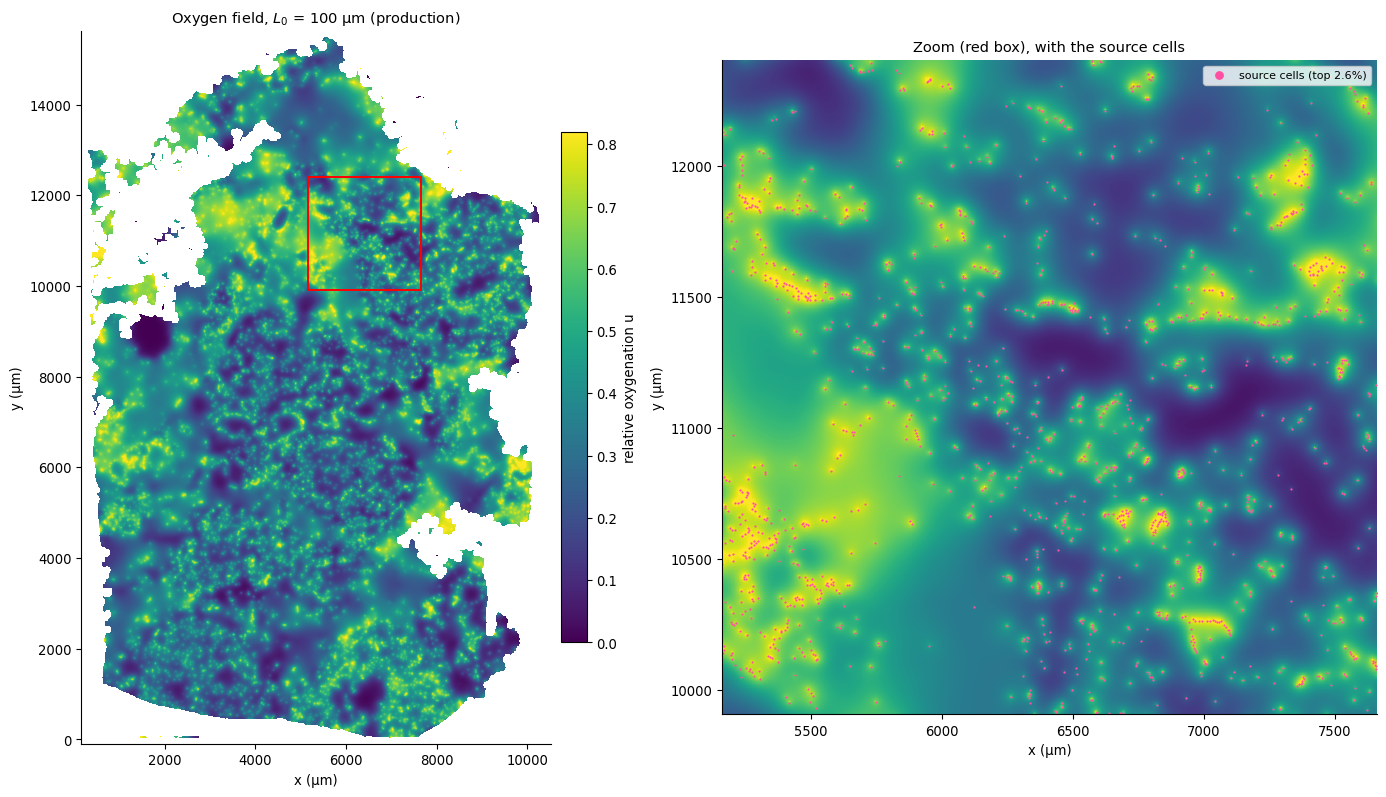

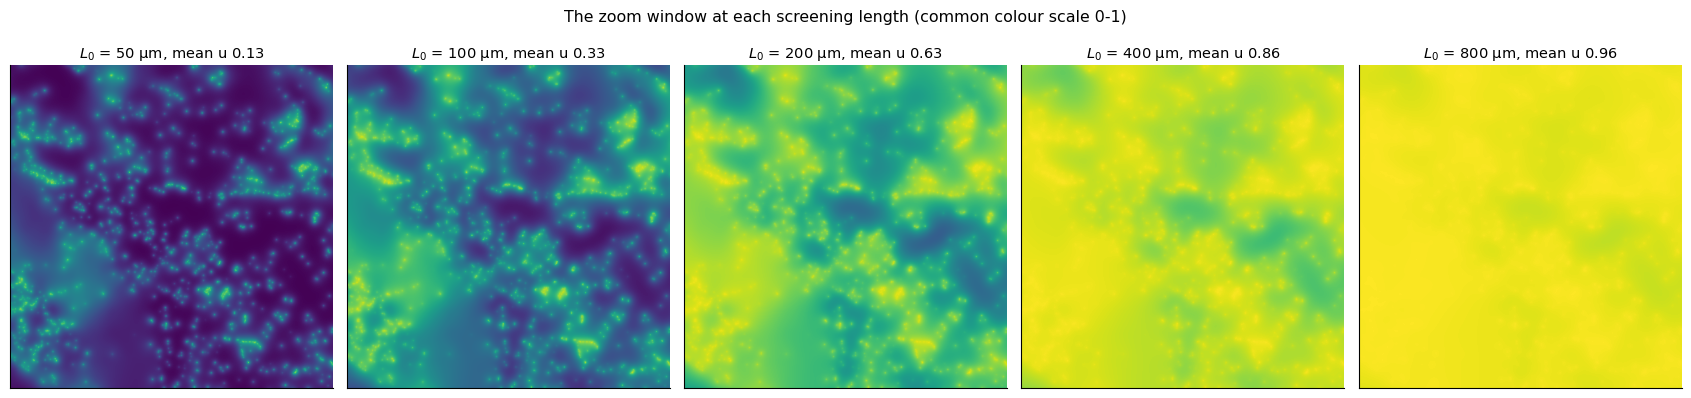

In [14]:
org, h = f100["origin"], f100["h"]
ext = [org[0], org[0] + R.shape[0] * h, org[1], org[1] + R.shape[1] * h]
(wi0, wi1), (wj0, wj1) = WIN
zext = [org[0] + wi0 * h, org[0] + wi1 * h, org[1] + wj0 * h, org[1] + wj1 * h]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [0.78, 1]})
im = ax.imshow(R.T, origin="lower", extent=ext, cmap="viridis", vmin=0, vmax=np.nanpercentile(R, 99.5))
ax.add_patch(plt.Rectangle((zext[0], zext[2]), zext[1] - zext[0], zext[3] - zext[2], fill=False, ec="red", lw=1.4))
fig.colorbar(im, ax=ax, fraction=0.05, pad=0.02, label="relative oxygenation u")
ax.set_title(r"Oxygen field, $L_0$ = 100 µm (production)"); ax.grid(False)
ax = ax2
w = fields[100.0]["window"]
ax.imshow(w.T, origin="lower", extent=zext, cmap="viridis", vmin=0, vmax=np.nanpercentile(w, 99.5))
s = (src_score > 0) & (src_xy[:, 0] > zext[0]) & (src_xy[:, 0] < zext[1]) & (src_xy[:, 1] > zext[2]) & (src_xy[:, 1] < zext[3])
ax.scatter(src_xy[s, 0], src_xy[s, 1], s=2.5, c="#ff4fa3", lw=0, label="source cells (top 2.6%)")
ax.legend(loc="upper right", fontsize=8, markerscale=4); ax.set_title("Zoom (red box), with the source cells"); ax.grid(False)
for a in (fig.axes[0], ax2): a.set_xlabel("x (µm)"); a.set_ylabel("y (µm)")
fig.tight_layout(); savefig(fig, "oxygen_field_maps")

fig, axes = plt.subplots(1, len(L0S), figsize=(17, 3.9))
for ax, L0 in zip(axes, L0S):
    ax.imshow(fields[L0]["window"].T, origin="lower", extent=zext, cmap="viridis", vmin=0, vmax=1)
    ax.set_title(rf"$L_0$ = {L0:.0f} µm, mean u {field_tab.loc[L0, 'mean u']:.2f}")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("The zoom window at each screening length (common colour scale 0-1)", y=1.02)
fig.tight_layout(); savefig(fig, "oxygen_field_by_L0")

### 3.1 Does the source mark vessels?

A field is only as good as its source. Marker-identified endothelium is used as
ground truth that does not depend on PhiSpace:
- **positives:** cells with ≥ 2 PECAM1 + CDH5 + CLDN5 counts, at least 3× their
  epithelial, T-cell, fibroblast and macrophage marker counts;
- **negatives:** cells with no endothelial counts and ≥ 3 other-lineage counts.

The AUROC asks how well a variable separates the two groups, scored at the
cells themselves. For $u$ that should be high, because endothelial cells sit at
the field's maxima. The decoys should score about 0.5.

In [15]:
gc_ = cells.set_index("cell_id").reindex(df["cell_id"])
endo_ct = gc_[[f"g_{m}" for m in nbb.ENDO_MARKERS]].sum(1).to_numpy()
other_ct = gc_[[f"g_{m}" for m in nbb.OTHER_MARKERS]].sum(1).to_numpy()
pos, neg = (endo_ct >= 2) & (endo_ct >= 3 * other_ct), (endo_ct == 0) & (other_ct >= 3)
print(f"marker endothelium {pos.sum():,} cells; marker-negative {neg.sum():,}")

def auroc(v):
    ok = np.isfinite(v) & (pos | neg)
    return roc_auc_score(pos[ok], v[ok])

auc = {"Endothelial PhiSpace score (the source)": auroc(gc_["phi_Endothelial"].to_numpy())}
for L0 in L0S:
    auc[f"u, L0 = {L0:.0f}"] = auroc(fields[L0]["u"])
for k in nbb.DECOYS:
    auc[f"decoy {k}, L0 = 100"] = auroc(f100["decoys"][k])
auc["u, L0 = 100, shallow cells also consume"] = auroc(f_all["u"])
auc_tab = pd.Series(auc, name="AUROC").to_frame()
auc_tab["(old SpaNorm field: 0.515)"] = ""
auc_tab.round(3)

marker endothelium 2,252 cells; marker-negative 27,973


,AUROC,(old SpaNorm field: 0.515)
Endothelial PhiSpace score (the source),0.985,
"u, L0 = 50",0.823,
"u, L0 = 100",0.788,
"u, L0 = 200",0.754,
"u, L0 = 400",0.735,
"u, L0 = 800",0.729,
"decoy rot180, L0 = 100",0.499,
"decoy flip_x, L0 = 100",0.507,
"decoy flip_y, L0 = 100",0.493,
"u, L0 = 100, shallow cells also consume",0.791,


### 3.2 The HIF-marker gate

The old §17 test, rerun on the new field: tile the section at 100 µm and ask
whether hypoxia-target expression falls where modelled oxygenation is high.
- Tiles need ≥ 20 cells.
- Rates are HIF-target transcripts per 1,000 total transcripts in the tile.
- The *partial* correlation ranks out tile depth, which inflated the old rates
  in shallow tissue.

The old core set had six genes. The Prime panel also carries a further ten
canonical HIF targets, used as an extended set. A clearly negative correlation
would license $u$ as a hypoxia proxy. A null is what the old notebook found,
and there it was blamed on the readout's sparsity.

In [16]:
genes_core = [g for g in nbb.HIF_CORE if f"g_{g}" in cells]
genes_ext = genes_core + [g for g in nbb.HIF_EXTENDED if f"g_{g}" in cells]
Tt = nbb.tiles(xc, yc, tile=100.0, min_cells=20)
tsum = lambda v: np.bincount(Tt["inv"], weights=v)[Tt["keep"]]
tot_t = tsum(gc_["total"].to_numpy(float))
logN_t = tsum(logN) / Tt["count"]

def partial_spearman(a, b, z):
    ra, rb, rz = (stats.rankdata(v) for v in (a, b, z))
    res = lambda v: v - np.polyval(np.polyfit(rz, v, 1), rz)
    return np.corrcoef(res(ra), res(rb))[0, 1]

rows = []
for lab, gl in (("core 6", genes_core), (f"extended {len(genes_ext)}", genes_ext)):
    rate = 1000 * tsum(gc_[[f"g_{g}" for g in gl]].sum(1).to_numpy(float)) / tot_t
    for L0 in L0S:
        ut = tsum(np.nan_to_num(fields[L0]["u"], nan=np.nanmean(fields[L0]["u"]))) / Tt["count"]
        rows.append({"genes": lab, "L0": L0, "Spearman(u, HIF rate)": stats.spearmanr(ut, rate).statistic,
                     "partial, depth ranked out": partial_spearman(ut, rate, logN_t)})
    rows.append({"genes": lab, "L0": "-", "Spearman(u, HIF rate)": stats.spearmanr(logN_t, rate).statistic,
                 "partial, depth ranked out": np.nan, "note": "row = Spearman(tile depth, HIF rate)"})
hif_tab = pd.DataFrame(rows)
print(f"{Tt['keep'].sum():,} tiles with >= 20 cells (median {np.median(Tt['count']):.0f} cells)")
per_gene = pd.DataFrame({g: {"cells detected %": 100 * (gc_[f"g_{g}"] > 0).mean(),
                             "tiles with zero %": 100 * (tsum(gc_[f"g_{g}"].to_numpy(float)) == 0).mean(),
                             "Spearman(u100, rate)": stats.spearmanr(
                                 tsum(np.nan_to_num(f100["u"])) / Tt["count"],
                                 tsum(gc_[f"g_{g}"].to_numpy(float)) / tot_t).statistic}
                         for g in genes_ext}).T
display(hif_tab.round(4)); per_gene.round(3)

7,624 tiles with >= 20 cells (median 64 cells)


,genes,L0,"Spearman(u, HIF rate)","partial, depth ranked out",note
0,core 6,50.0,0.2719,0.2336,NaN
1,core 6,100.0,0.2664,0.2244,NaN
2,core 6,200.0,0.2525,0.2104,NaN
3,core 6,400.0,0.2421,0.2011,NaN
4,core 6,800.0,0.2374,0.1971,NaN
5,core 6,-,-0.3669,NaN,"row = Spearman(tile depth, HIF rate)"
6,extended 16,50.0,0.2027,0.1507,NaN
7,extended 16,100.0,0.1974,0.1405,NaN
8,extended 16,200.0,0.1860,0.1291,NaN
9,extended 16,400.0,0.1782,0.1228,NaN


,cells detected %,tiles with zero %,"Spearman(u100, rate)"
CA9,0.242,84.942,-0.086
NDRG1,5.306,11.988,0.229
ADM,1.239,55.155,0.068
EGLN3,0.642,66.041,0.012
BNIP3,1.294,54.499,-0.149
ANGPTL4,0.716,67.550,0.085
VEGFA,7.177,10.113,0.072
SLC2A1,3.997,31.676,-0.194
PGK1,4.459,16.330,-0.013
LDHA,14.007,2.886,0.118


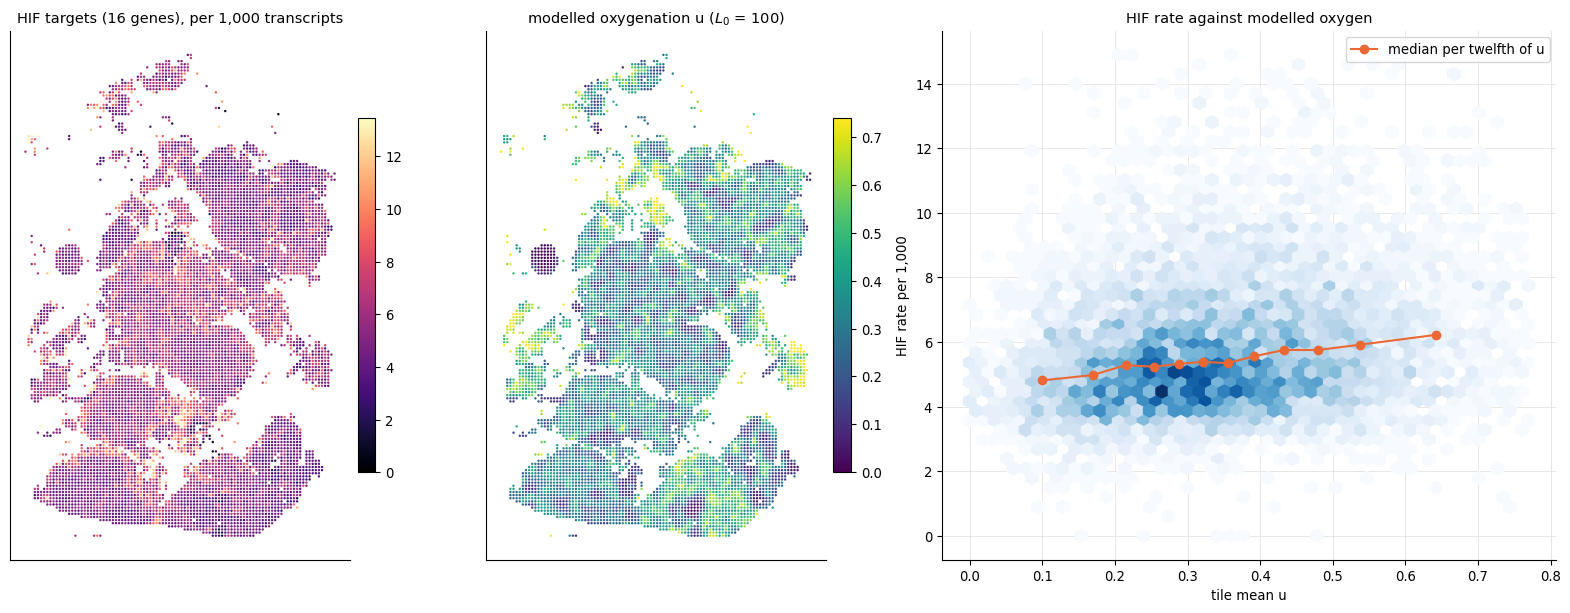

In [17]:
rate_ext = 1000 * tsum(gc_[[f"g_{g}" for g in genes_ext]].sum(1).to_numpy(float)) / tot_t
ut100 = tsum(np.nan_to_num(f100["u"])) / Tt["count"]
fig, axes = plt.subplots(1, 3, figsize=(16, 6.2), gridspec_kw={"width_ratios": [0.72, 0.72, 1.15]})
for ax, v, lab, cm in ((axes[0], rate_ext, f"HIF targets ({len(genes_ext)} genes), per 1,000 transcripts", "magma"),
                       (axes[1], ut100, r"modelled oxygenation u ($L_0$ = 100)", "viridis")):
    sc_ = ax.scatter(Tt["xy"][:, 0], Tt["xy"][:, 1], c=v, s=3, lw=0, cmap=cm,
                     vmin=0, vmax=np.percentile(v, 99))
    fig.colorbar(sc_, ax=ax, fraction=0.046, pad=0.02); ax.set_aspect("equal"); ax.set_title(lab)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax = axes[2]
ax.hexbin(ut100, rate_ext, gridsize=45, cmap="Blues", mincnt=1,
          extent=(0, np.percentile(ut100, 99.5), 0, np.percentile(rate_ext, 99.5)))
q = pd.qcut(ut100, 12, duplicates="drop")
med = pd.DataFrame({"u": ut100, "r": rate_ext}).groupby(q, observed=True).median()
ax.plot(med["u"], med["r"], "o-", color=COL["decoy"], label="median per twelfth of u")
ax.set_xlabel("tile mean u"); ax.set_ylabel("HIF rate per 1,000"); ax.legend(); ax.set_title("HIF rate against modelled oxygen")
fig.tight_layout(); savefig(fig, "oxygen_hif_gate")

### 3.3 Does $u$ explain division beyond cell state? Decoys and the $L_0$ sweep

The old §18 and §20, rerun with three decoys instead of one. Any smooth spatial
covariate soaks up some residual autocorrelation for free. So $u$ is judged
against the same raster:
- rotated 180° (point-reflected through the raster centre);
- mirrored in x;
- mirrored in y.

Each decoy has identical smoothness and marginal distribution, but is
misaligned with the tissue.

Every fit runs on one common cell set: cells inside the tissue mask under the
real field, all three decoys, and the all-consumers variant. That keeps every
likelihood and Moran's I comparable. The mask does not depend on $L_0$.

Each covariate is z-scored, so $\psi$ is the effect per SD of $u$ and is
comparable across $L_0$. The reference fit is the baseline on the common set, which has no oxygen term.
Each row of the table is one fit with one covariate added. Two measures compare real and
decoy:
- the drop in residual Moran's I, at the 100 µm tile scale;
- the likelihood gain.

In [18]:
valid = np.isfinite(f_all["u"])
for L0, F in fields.items():
    valid &= np.isfinite(F["u"])
    for k in nbb.DECOYS:
        valid &= np.isfinite(F["decoys"][k])
O = np.flatnonzero(valid)
T_O = nbb.tiles(xc[O], yc[O])
zs = lambda v: (v - v.mean()) / v.std()
print(f"common oxygen cell set: {len(O):,} cells ({100 * len(O) / n:.1f}%), {T_O['keep'].sum():,} tiles")

ox_base = nbb.cached("ox_base", lambda: nbb.fit(nbb.subset(D, O), init=base_fit["params"],
                                                say=print, **BASE, **PEN))
COVS = {(L0, kind): (fields[L0]["u"] if kind == "real" else fields[L0]["decoys"][kind])
        for L0 in L0S for kind in ("real",) + nbb.DECOYS}
COVS[(100.0, "all consumers")] = f_all["u"]
ox = {}
for (L0, kind), v in COVS.items():
    tag = f"ox_L{int(L0)}_{kind.replace(' ', '_')}"
    ox[(L0, kind)] = nbb.cached(tag, lambda v=v: nbb.fit(nbb.subset(D, O, oxygen=zs(v[O])),
                                                          init=ox_base["params"], say=print, **BASE, **PEN))

common oxygen cell set: 390,545 cells (69.5%), 7,100 tiles


In [19]:
yO = y[O]
I_base = nbb.tile_moran(nbb.pearson(yO, ox_base["mu"], ox_base["alpha"]), T_O, permutations=0)["I"]
rows = []
for (L0, kind), f in ox.items():
    v = COVS[(L0, kind)][O]
    psi, C = nbb.estimate(f, "psi")
    I = nbb.tile_moran(nbb.pearson(yO, f["mu"], f["alpha"]), T_O, permutations=0)["I"]
    rows.append({"L0": L0, "covariate": kind, "psi per SD": psi[0], "se": np.sqrt(C[0, 0]),
                 "z": psi[0] / np.sqrt(C[0, 0]), "LR vs no oxygen": 2 * (f["loglik"] - ox_base["loglik"]),
                 "resid Moran I": I, "Moran reduction": I_base - I,
                 "corr(cov, log N)": np.corrcoef(v, logN[O])[0, 1], "converged": f["info"]["converged"],
                 "attempts": f["info"].get("attempts", 1)})
ox_tab = pd.DataFrame(rows)
dec = ox_tab[ox_tab["covariate"].isin(nbb.DECOYS)].groupby("L0")
real = ox_tab[ox_tab["covariate"] == "real"].set_index("L0")
sweep = pd.DataFrame({
    "psi per SD": real["psi per SD"], "z": real["z"], "LR": real["LR vs no oxygen"],
    "decoy |z| max": dec["z"].apply(lambda s: s.abs().max()),
    "decoy LR max": dec["LR vs no oxygen"].max(),
    "Moran reduction": real["Moran reduction"],
    "decoy reduction mean": dec["Moran reduction"].mean(),
    "decoy reduction max": dec["Moran reduction"].max(),
    "corr(u, log N)": real["corr(cov, log N)"]})
sweep["LR margin over best decoy"] = sweep["LR"] / sweep["decoy LR max"].clip(lower=1e-9)
ox_tab.to_csv(OUT / "oxygen_fits.csv", index=False); sweep.to_csv(OUT / "oxygen_sweep.csv")
print(f"no-oxygen reference on the common set: residual Moran's I = {I_base:.4f}")
display(ox_tab[ox_tab["L0"] == 100.0].set_index("covariate").drop(columns="L0").round(4))
sweep.round(4)

no-oxygen reference on the common set: residual Moran's I = 0.0535


,psi per SD,se,z,LR vs no oxygen,resid Moran I,Moran reduction,"corr(cov, log N)",converged,attempts
covariate,,,,,,,,,
real,0.0142,0.0049,2.8906,9.1175,0.0536,-0.0001,-0.0708,True,1
rot180,0.0066,0.0030,2.2149,4.8884,0.0537,-0.0002,0.0213,True,1
flip_x,0.0018,0.0031,0.5883,0.3515,0.0535,0.0000,-0.0552,True,1
flip_y,0.0069,0.0029,2.3448,5.5523,0.0536,-0.0001,0.0474,True,1
all consumers,0.0126,0.0046,2.7387,8.1679,0.0539,-0.0004,-0.0098,True,1


,psi per SD,z,LR,decoy |z| max,decoy LR max,Moran reduction,decoy reduction mean,decoy reduction max,"corr(u, log N)",LR margin over best decoy
L0,,,,,,,,,,
50.0,0.0155,2.9489,9.6247,1.5436,2.3660,0.0000,-0.0000,0.0000,-0.0604,4.0679
100.0,0.0142,2.8906,9.1175,2.3448,5.5523,-0.0001,-0.0001,0.0000,-0.0708,1.6421
200.0,0.0059,1.3614,2.0864,3.3918,11.6027,-0.0001,-0.0001,-0.0000,-0.0602,0.1798
400.0,-0.0008,-0.2206,0.0285,3.9143,15.5339,0.0000,0.0001,0.0001,-0.0403,0.0018
800.0,-0.0034,-0.9205,0.8038,3.4509,12.2059,0.0001,0.0003,0.0006,-0.0215,0.0659


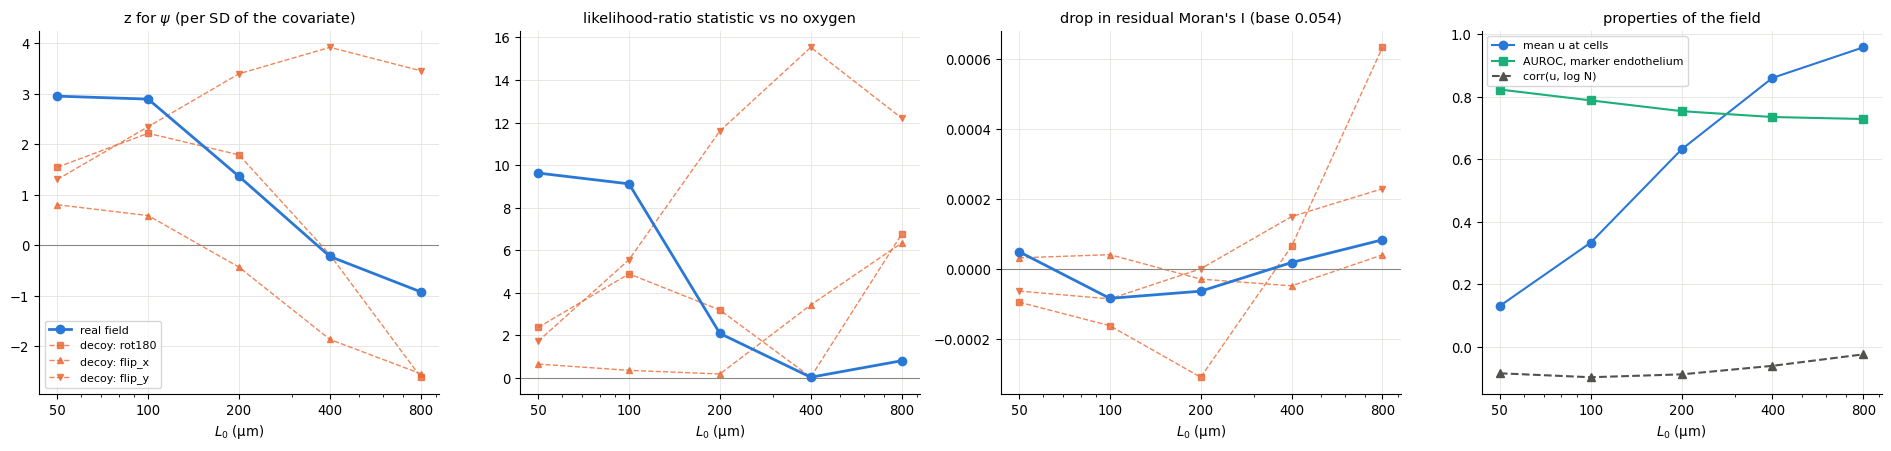

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
L = np.array(L0S)
dz = ox_tab[ox_tab["covariate"].isin(nbb.DECOYS)]
for ax, col, lab in ((axes[0], "z", r"z for $\psi$ (per SD of the covariate)"),
                     (axes[1], "LR vs no oxygen", "likelihood-ratio statistic vs no oxygen"),
                     (axes[2], "Moran reduction", f"drop in residual Moran's I (base {I_base:.3f})")):
    ax.plot(L, real[col], "o-", color=COL["real"], lw=2, label="real field", zorder=3)
    for k, mk in zip(nbb.DECOYS, ("s", "^", "v")):
        d = dz[dz["covariate"] == k].set_index("L0")[col]
        ax.plot(L, d, mk + "--", color=COL["decoy"], ms=5, lw=1, alpha=0.8, label=f"decoy: {k}")
    ax.axhline(0, color=MUTED, lw=0.8); ax.set_xscale("log"); ax.set_xticks(L); ax.set_xticklabels([f"{v:.0f}" for v in L])
    ax.set_xlabel(r"$L_0$ (µm)"); ax.set_title(lab)
axes[0].legend(fontsize=8)
ax = axes[3]
ax.plot(L, field_tab["mean u"], "o-", color=COL["real"], label="mean u at cells")
ax.plot(L, [auc_tab.loc[f"u, L0 = {v:.0f}", "AUROC"] for v in L], "s-", color=COL["alt"], label="AUROC, marker endothelium")
ax.plot(L, field_tab["corr(u, log N)"], "^--", color=COL["base"], label="corr(u, log N)")
ax.set_xscale("log"); ax.set_xticks(L); ax.set_xticklabels([f"{v:.0f}" for v in L])
ax.set_xlabel(r"$L_0$ (µm)"); ax.set_title("properties of the field"); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "oxygen_sweep")

### Reading §3

**The field marks vessels.** The source scores AUROC 0.985 against
marker-identified endothelium, and $u$ scores 0.79 at $L_0$ = 100 µm. The decoys
score 0.5, and corr$(u, \log N) = -0.10$. The old SpaNorm field scored 0.515 and
correlated +0.49 with depth. (The field depends on neither the weight model nor
the technical terms.)

**The HIF gate still fails.** Across 100 µm tiles, Spearman$(u,$ HIF rate$)$ is
+0.27 (6 genes) and +0.20 (16 genes), and stays positive with depth ranked out.
The composite is dominated by NDRG1, LDHA and PFKFB3, which all rise with $u$.
The specific markers (CA9, BNIP3, SLC2A1) fall with $u$, as they should, but
only weakly.

**$u$ adds almost nothing about division beyond cell state.**
- $|\psi| \le 0.016$ per SD at every $L_0$. The short-range effect is
  positive (more oxygen, more division).
  - At $L_0$ = 50 µm it is +0.016 per SD (z 2.9).
  - At 100 µm it is +0.014 (z 2.9).
  - The first run, under the earlier weight model, gave −0.010.
- At the production $L_0$ = 100 µm, the real field gains LR 9.1, against 5.6
  for its y-mirror and 4.9 for its rotation: a margin of 1.6×.
- Only $L_0$ = 50 µm leads its decoys clearly (9.6 against at most 2.4).
- From 200 µm upward the decoys beat the real field (LR up to 11.6–15.5 against
  0.03–2.1).
- Residual Moran's I (0.054) falls by at most 0.0001.
- Letting shallow cells consume oxygen changes little ($\psi$ 0.0126 against
  0.0142).

A real field that beats its decoys only at the shortest screening length, by an
effect of under 2% per SD, is what short-range vessel proximity would look like
if it were mostly already in $\eta$ through the neighbours' Endothelial score.
The old notebook's 13× margin over the rotated decoy belonged to a field that
tracked depth.

**Decision (user, 2026-10-06): oxygen is dropped from every model.** The MisTIC
rerun does not change it.

## 4. The annulus test: real neighbourhood effect, or segmentation spillover?

The 80 µm disc conflates two mechanisms:
- a **genuine neighbourhood effect**, where who surrounds a cell matters;
- **segmentation spillover**, where transcripts from a touching neighbour are
  assigned to this cell, so $\bar\phi$ partly echoes the cell's own
  mismeasured state.

Spillover is a contact artefact: it acts only between cells whose boundaries
touch. So the model is refit with $\bar\phi$ taken over successive rings, at
0–15, 15–30, 30–50, 50–80, 80–120 and 120–200 µm, and we watch the neighbour
effect move outward.

**The null.** Under pure spillover, a ring's coefficient is inherited from how
much its mean state still resembles the cell's own state:
$\hat c(r) = k\,\rho_\phi(r)$, where $\rho_\phi(r)$ is the PhiSpace correlogram
over every pair in the ring.

**Count matching.** A wide ring averages many more cells, so its $\bar\phi$ is
measured with less noise and suffers less regression dilution. That alone
inflates its coefficient. The count-matched control thins every ring at random
to the innermost ring's mean count, so all rings carry the same averaging noise.
This is the version to trust.

**Mechanics.**
- The neighbour pool is every typed cell, including the 2,107 outside the
  oxygen mask. Shallow cells are excluded, as in production.
- Each ring's mean replaces the neighbour block, as a single 8-coordinate
  block; the rest of the model is the baseline (offset, no oxygen). Every ring
  is centred, projected and whitened with **one common matrix**, the one that
  whitens the 80 µm disc mean. Per-ring whitening would rotate the coordinates
  from ring to ring, and the spillover test compares coordinate $d$ across
  rings.
- All rings are fit on one cell set: cells with at least one typed neighbour
  in every ring.
- Effects are reported per SD of the ring mean, per cell type $k$:
  $\beta_k = (Qc)_k \cdot \mathrm{sd}(\bar\phi_k)$.
- The spillover χ² runs on the eight projected coordinates. Unlike the nine
  cell-type effects, which sum to zero, these are not linearly dependent.

In [21]:
pool = cells.loc[cells["typed"]].reset_index(drop=True)
pxy = pool[["x", "y"]].to_numpy(float)
P = pool[[f"phi_{t}" for t in TYPES]].to_numpy(float)
focal = pd.Series(np.arange(len(pool)), index=pool["cell_id"]).reindex(df["cell_id"]).to_numpy()
# one projection for every ring: sum-to-zero, then the whitening of the 80 um disc mean
disc_all = df[[f"nbr_phi_{j:02d}" for j in range(len(TYPES))]].to_numpy(float)
_, Q_RING = nbb.project_block(disc_all, basis)
ring_proj = lambda Pb: (Pb - Pb.mean(0)) @ Q_RING
Pc = P - P.mean(0); Pq = Pc @ Q_RING
Zrho = np.column_stack([Pc / Pc.std(0), Pq / Pq.std(0)])      # 9 type scores, then 8 projected coords
cnt0 = nbb.ring_counts(pxy, focal, nbb.RINGS[0][1])
K_MATCH = int(round(cnt0.mean()))
ann = nbb.cached("annulus_rings_whitened", lambda: nbb.ring_means(pxy, P, focal, Zrho,
                                                                  max_neighbors=K_MATCH))
A = np.flatnonzero((ann["count"] > 0).all(0))
ring_lab = [f"{a:.0f}-{b:.0f}" for a, b in nbb.RINGS]
ring_tab = pd.DataFrame({"ring (µm)": ring_lab,
                         "mean neighbours": ann["count"].mean(1),
                         "count-matched": ann["count_matched"].mean(1),
                         "no neighbour %": 100 * (ann["count"] == 0).mean(1),
                         "pairs": ann["n_pairs"],
                         "rho (mean over types)": ann["rho"][:, :len(TYPES)].mean(1)}).set_index("ring (µm)")
print(f"count matching thins every ring to <= {K_MATCH} neighbours (the 0-15 µm mean is {cnt0.mean():.2f})")
print(f"annulus cell set: {len(A):,} cells ({100 * len(A) / n:.1f}%) with a typed neighbour in every ring")
ring_tab.round(3)

count matching thins every ring to <= 6 neighbours (the 0-15 µm mean is 6.31)
annulus cell set: 539,359 cells (96.0%) with a typed neighbour in every ring


,mean neighbours,count-matched,no neighbour %,pairs,rho (mean over types)
ring (µm),,,,,
0-15,6.312,4.590,3.484,3.5465e+06,0.256
15-30,18.665,5.727,0.969,1.0488e+07,0.191
30-50,42.175,5.893,0.272,2.3698e+07,0.157
50-80,98.498,5.976,0.033,5.5346e+07,0.131
80-120,193.199,5.996,0.009,1.0856e+08,0.106
120-200,583.917,6.000,0.001,3.2810e+08,0.078


In [22]:
ring_bar = {}
for r, lab in enumerate(ring_lab):
    for kind, S, Cn in (("naive", ann["sum"], ann["count"]), ("matched", ann["sum_matched"], ann["count_matched"])):
        ring_bar[(kind, lab)] = S[r][A] / Cn[r][A][:, None]
prod_bar = disc_all[A]                    # the 80 um disc mean, the annulus set's reference
DA = nbb.subset(D, A)                     # the production design (contact/regional split) on that set
ann_fit = {"none": nbb.cached("ann_nonbr", lambda: nbb.fit(nbb.subset(D, A, nbr=np.zeros((len(A), 8))),
                                                           init=base_fit["params"], say=print, **BASE, **PEN)),
           "disc 0-80": nbb.cached("ann_disc80", lambda: nbb.fit(nbb.subset(D, A, nbr=ring_proj(prod_bar)),
                                                                 init=base_fit["params"], say=print, **BASE, **PEN))}
for (kind, lab), Pb in ring_bar.items():
    ann_fit[(kind, lab)] = nbb.cached(f"ann_{kind}_{lab}", lambda Pb=Pb: nbb.fit(
        nbb.subset(D, A, nbr=ring_proj(Pb)), init=base_fit["params"], say=print, **BASE, **PEN))

In [23]:
def ring_effects(f, Pb):
    proj = ring_proj(Pb); sdp = proj.std(0); sdt = Pb.std(0)
    vt, Ct = nbb.estimate(f, "c", Q_RING)
    vp, Cp = nbb.estimate(f, "c")
    U, V = f["params"]["U"], f["params"]["V"]
    sig = np.linalg.svd(U @ V.T * sdp[None, :], compute_uv=False)
    return dict(beta=vt * sdt, beta_se=np.sqrt(np.diag(Ct)) * sdt,
                cproj=vp * sdp, cproj_se=np.sqrt(np.diag(Cp)) * sdp, sigma1_B=sig[0], sigma2_B=sig[1])

ll0 = ann_fit["none"]["loglik"]
summ, coef_rows, per_type = [], [], {}
for kind in ("naive", "matched"):
    for r, lab in enumerate(ring_lab):
        f = ann_fit[(kind, lab)]; e = ring_effects(f, ring_bar[(kind, lab)])
        summ.append({"version": kind, "ring": lab, "mean |beta|": np.abs(e["beta"]).mean(),
                     "||beta||": np.linalg.norm(e["beta"]), "sigma1(B) per SD": e["sigma1_B"],
                     "neighbour-block LR": 2 * (f["loglik"] - ll0),
                     "rho": ann["rho"][r, :len(TYPES)].mean(), "converged": f["info"]["converged"]})
        per_type[(kind, lab)] = pd.Series(e["beta"], index=TYPES)
        for d in range(len(e["cproj"])):
            coef_rows.append({"version": kind, "r_inner": nbb.RINGS[r][0], "r_outer": nbb.RINGS[r][1],
                              "dim": f"q{d + 1}", "c": e["cproj"][d], "se": e["cproj_se"][d],
                              "rho_pair": ann["rho"][r, len(TYPES) + d]})
ed = ring_effects(ann_fit["disc 0-80"], prod_bar)
summ.append({"version": "reference", "ring": "disc 0-80", "mean |beta|": np.abs(ed["beta"]).mean(),
             "||beta||": np.linalg.norm(ed["beta"]), "sigma1(B) per SD": ed["sigma1_B"],
             "neighbour-block LR": 2 * (ann_fit["disc 0-80"]["loglik"] - ll0), "rho": np.nan,
             "converged": ann_fit["disc 0-80"]["info"]["converged"]})
ann_tab = pd.DataFrame(summ)
for kind in ("naive", "matched"):
    m = ann_tab["version"] == kind
    b0, r0 = ann_tab.loc[m, "mean |beta|"].iloc[0], ann_tab.loc[m, "rho"].iloc[0]
    ann_tab.loc[m, "beta(r)/beta(0)"] = ann_tab.loc[m, "mean |beta|"] / b0
    ann_tab.loc[m, "rho(r)/rho(0)"] = ann_tab.loc[m, "rho"] / r0
ann_tab["ratio"] = ann_tab["beta(r)/beta(0)"] / ann_tab["rho(r)/rho(0)"]
coef = pd.DataFrame(coef_rows)
chi = {kind: spillover_chi2(coef[coef["version"] == kind]) for kind in ("naive", "matched")}
for kind, res in chi.items():
    print(f"spillover null c_d(r) = k_d rho_d(r), {kind}: chi2 = {res['chi2']:.0f} on {res['df']} df")
ann_tab.to_csv(OUT / "annulus.csv", index=False)
ann_tab.round(4)

spillover null c_d(r) = k_d rho_d(r), naive: chi2 = 793 on 40 df
spillover null c_d(r) = k_d rho_d(r), matched: chi2 = 470 on 40 df


,version,ring,mean |beta|,||beta||,sigma1(B) per SD,neighbour-block LR,rho,converged,beta(r)/beta(0),rho(r)/rho(0),ratio
0,naive,0-15,0.0358,0.1555,0.3140,3706.0063,0.2563,True,1.0000,1.0000,1.0000
1,naive,15-30,0.0292,0.1144,0.2299,3277.2453,0.1913,True,0.8148,0.7465,1.0914
2,naive,30-50,0.0258,0.1004,0.1751,2783.1579,0.1573,True,0.7219,0.6137,1.1764
3,naive,50-80,0.0246,0.0973,0.1294,2433.8420,0.1306,True,0.6859,0.5098,1.3456
4,naive,80-120,0.0261,0.1069,0.0956,2127.7593,0.1059,True,0.7284,0.4132,1.7629
5,naive,120-200,0.0316,0.1281,0.0658,1949.4822,0.0776,True,0.8816,0.3027,2.9125
6,matched,0-15,0.0347,0.1502,0.3123,3566.0157,0.2563,True,1.0000,1.0000,1.0000
7,matched,15-30,0.0231,0.0945,0.2370,2563.1715,0.1913,True,0.6652,0.7465,0.8910
8,matched,30-50,0.0162,0.0696,0.1855,1780.0436,0.1573,True,0.4686,0.6137,0.7636
9,matched,50-80,0.0142,0.0577,0.1451,1306.9918,0.1306,True,0.4108,0.5098,0.8059


In [24]:
# Per-type neighbour effects (per SD of the ring mean), count-matched rings, beside the 80 um disc
bt = pd.DataFrame({lab: per_type[("matched", lab)] for lab in ring_lab})
bt["disc 0-80"] = pd.Series(ed["beta"], index=TYPES)
bt["120-200 / 0-15"] = bt["120-200"] / bt["0-15"]
bt.round(3)

,0-15,15-30,30-50,50-80,80-120,120-200,disc 0-80,120-200 / 0-15
Endothelial,-0.042,-0.033,-0.029,-0.023,-0.022,-0.019,-0.050,0.449
CAFs,-0.015,-0.013,-0.006,-0.007,-0.003,-0.005,-0.010,0.331
PVL,-0.017,-0.004,-0.006,-0.003,-0.004,-0.002,0.012,0.117
B-cells,-0.013,-0.011,-0.007,-0.006,-0.008,-0.009,-0.006,0.678
T-cells,0.028,0.010,0.006,0.007,0.011,0.007,0.019,0.243
Myeloid,-0.028,-0.025,-0.008,-0.005,-0.001,0.001,-0.011,-0.033
Normal Epithelial,-0.015,-0.006,-0.007,-0.014,-0.014,-0.010,-0.040,0.660
Plasmablasts,0.019,0.026,0.019,0.018,0.013,0.015,0.034,0.778
Cancer Epithelial,0.134,0.078,0.058,0.046,0.046,0.027,0.090,0.202


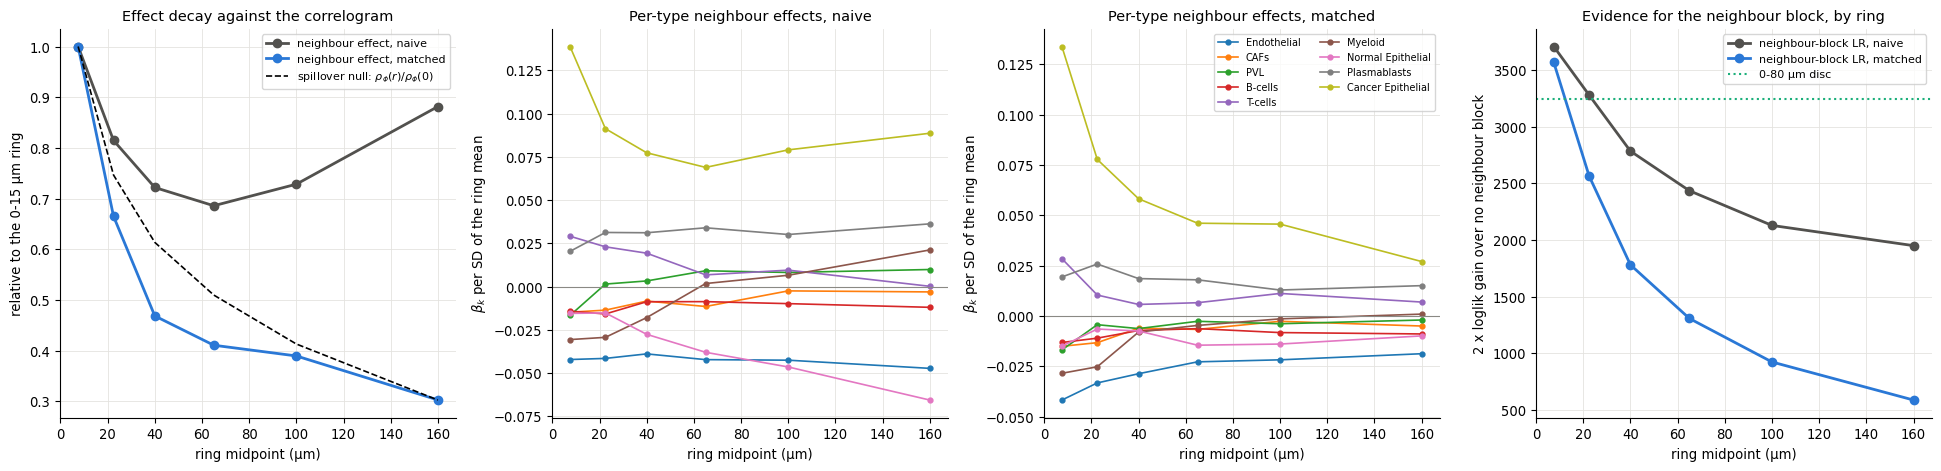

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(19.5, 4.8))
mid = np.array([(a + b) / 2 for a, b in nbb.RINGS])
ax = axes[0]
for kind, c in (("naive", COL["base"]), ("matched", COL["real"])):
    t = ann_tab[ann_tab["version"] == kind]
    ax.plot(mid, t["beta(r)/beta(0)"], "o-", color=c, lw=2, label=f"neighbour effect, {kind}")
ax.plot(mid, ann_tab[ann_tab["version"] == "matched"]["rho(r)/rho(0)"], "k--", lw=1.2,
        label=r"spillover null: $\rho_\phi(r)/\rho_\phi(0)$")
ax.set_xlabel("ring midpoint (µm)"); ax.set_ylabel("relative to the 0-15 µm ring"); ax.legend(fontsize=8)
ax.set_title("Effect decay against the correlogram")
for ax, kind in ((axes[1], "naive"), (axes[2], "matched")):
    M = pd.DataFrame({lab: per_type[(kind, lab)] for lab in ring_lab})
    for t in TYPES:
        ax.plot(mid, M.loc[t], "o-", ms=3.5, lw=1.2, label=t)
    ax.axhline(0, color=MUTED, lw=0.8); ax.set_xlabel("ring midpoint (µm)")
    ax.set_ylabel(r"$\beta_k$ per SD of the ring mean"); ax.set_title(f"Per-type neighbour effects, {kind}")
axes[2].legend(fontsize=7, ncol=2)
ax = axes[3]
for kind, c in (("naive", COL["base"]), ("matched", COL["real"])):
    t = ann_tab[ann_tab["version"] == kind]
    ax.plot(mid, t["neighbour-block LR"], "o-", color=c, lw=2, label=f"neighbour-block LR, {kind}")
ax.axhline(ann_tab.loc[ann_tab["version"] == "reference", "neighbour-block LR"].iloc[0], color=COL["alt"],
           ls=":", lw=1.5, label="0-80 µm disc")
ax.set_xlabel("ring midpoint (µm)"); ax.set_ylabel("2 x loglik gain over no neighbour block")
ax.set_title("Evidence for the neighbour block, by ring"); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "annulus")

### Reading §4

**Naive rings repeat the old dilution artefact.** The effect dips to 0.69× by
50–80 µm, then climbs back to 0.88× at 120–200 µm, where each ring mean averages
584 cells instead of 6. Its ratio to the correlogram reaches 2.9.

**With count matching, the effect decays in step with the correlogram.** Each
ring holds at most 6 neighbours.

| ring (µm) | 0–15 | 15–30 | 30–50 | 50–80 | 80–120 | 120–200 |
|---|---|---|---|---|---|---|
| neighbour effect, relative | 1 | 0.67 | 0.47 | 0.41 | 0.39 | 0.30 |
| $\rho_\phi$, relative | 1 | 0.75 | 0.61 | 0.51 | 0.41 | 0.30 |
| ratio | 1 | 0.89 | 0.76 | 0.81 | 0.94 | 1.00 |

- The old notebook's ratios of 1.1–1.4, read as an effect with its own range, do
  not replicate.
- The χ² for exact proportionality is 470 on 40 df.
  It is approximate (model-based SEs, every ring fit on the same cells), and the
  shape is the robust part.

**What this says.** Spillover cannot act at 120–200 µm, yet 30% of the contact
effect remains there (neighbour-block LR 587). The far effect is regional
composition, falling off as fast as composition decorrelates. The 0–15 µm ring
alone (at most 6 cells) still carries more evidence than the whole 80 µm disc
(LR 3,566 against 3,244).

**The MisTIC term.** $\theta_m m$ takes up part of the contact-range variation, as
modelled spillover should. It does not remove the neighbourhood effect (Cancer
Epithelial 0.134 per SD at contact), and what remains decays like regional
composition, not like a contact artefact.

**By cell type.**
- Cancer Epithelial carries the largest effect at every ring (0.134 per SD at
  contact, 0.027 at 120–200 µm).
- The Endothelial effect is negative throughout (−0.042 to −0.019).
- The T-cell effect is a contact effect (0.028 to 0.007).
- Plasmablasts are flattest (0.019 to 0.015).

## 5. Neighbourhood structure: how should $\bar\phi$ weight its neighbours?

§4 found that the contact ring carries the most information. The 80 µm disc
weights every neighbour equally, so it dilutes the closest cells with about
95 more distant ones. Here several alternatives compete as *predictors*, all
on the annulus cell set with the baseline model.

- **Uniform disc 0–80 µm.** The neighbour block until 2026-10-07, and the
  reference every model is scored against.
- **Split, two blocks:** contact (0–15 µm) and regional (15–80 µm) means,
  production since 2026-10-07. Each
  gets its own main effect $c$ and its own rows of $V$, so the bilinear term
  reads $(\phi^\top U)(\bar\phi_\text{contact}^\top V_1 + \bar\phi_\text{regional}^\top V_2)$.
  This doubles the neighbour block (+32 parameters at rank 3).
- **Split, three blocks:** adds a far block (80–200 µm), testing whether
  anything beyond 80 µm helps.
- **Six rings:** every annulus as its own block. This is the nonparametric
  distance profile and the upper bound on what any weighting could achieve
  (+160 parameters).
- **Exponential decay:**
  $\bar\phi_i = \sum_j w_{ij}\phi_j / \sum_j w_{ij}$ with
  $w_{ij} = e^{-d_{ij}/\ell}$ out to 200 µm, for
  $\ell \in \{5, 10, 20, 40, 80, 160\}$ µm. This has the same parameter count
  as the disc. $\ell$ is profiled over the grid: the best $\ell$ is the kernel
  the data prefer.

Each neighbourhood block is centred, projected and whitened by its own
covariance, as the production basis treats the contact and regional blocks.

In-sample likelihood rewards the bigger blocks automatically, and spatial
autocorrelation makes AIC and BIC too lenient. The arbiter is therefore
**spatial 5-fold cross-validation**:
- folds are the stored map from the mixture's CV (contiguous blocks;
  `outputs/division_classifier/folds.parquet`, written on Spartan);
- the criterion is the held-out NB log-likelihood.

**A caution on contact terms.** Segmentation spillover acts exactly at contact,
so a model that up-weights touching cells can partly be fitting the artefact,
not biology. The split model makes the contact block explicit, so its effects
can be compared with the own-state effects.

In [26]:
def ring_mean(rs):
    S = sum(ann["sum"][r] for r in rs)[A]; Cn = sum(ann["count"][r] for r in rs)[A]
    return S / Cn[:, None]

print(f"0-80 µm disc rebuilt from the rings vs the table's 80 µm disc mean: max |difference| "
      f"{np.abs(ring_mean([0, 1, 2, 3]) - prod_bar).max():.1e}")
BLOCKS = {"contact": ring_mean([0]), "regional": ring_mean([1, 2, 3]), "far": ring_mean([4, 5])}
ELLS = (5.0, 10.0, 20.0, 40.0, 80.0, 160.0)
kern = nbb.cached("kernel_means", lambda: nbb.kernel_means(pxy, P, focal, ELLS))
K_BAR = {ell: (kern["sum"][e] / kern["W"][e][:, None])[A] for e, ell in enumerate(ELLS)}
neff = {ell: float(np.median((kern["W"][e] ** 2 / kern["W2"][e])[A])) for e, ell in enumerate(ELLS)}

prod_split = np.hstack([df[[f"{pre}{j:02d}" for j in range(len(TYPES))]].to_numpy(float)[A]
                        for pre in ("nbrc_phi_", "nbrr_phi_")])
print(f"contact + regional rebuilt from the rings vs the production split columns: max |difference| "
      f"{np.abs(np.hstack([BLOCKS['contact'], BLOCKS['regional']]) - prod_split).max():.1e}")
DISC, SPLIT = "disc 0-80", "split: contact + regional"
NBR, NBRQ = {}, {}
for name, blocks in ((DISC, [prod_bar]), (SPLIT, [BLOCKS["contact"], BLOCKS["regional"]]),
                     ("split: contact + regional + far", [BLOCKS["contact"], BLOCKS["regional"], BLOCKS["far"]]),
                     ("six rings", [ring_mean([r]) for r in range(6)])):
    NBR[name], NBRQ[name] = nbb.stack_nbr(blocks, basis, return_q=True)
for ell in ELLS:
    NBR[f"exp, ell = {ell:.0f}"], NBRQ[f"exp, ell = {ell:.0f}"] = nbb.stack_nbr([K_BAR[ell]], basis, return_q=True)
TAG = {k: k.replace("split: ", "split_").replace(" + ", "_").replace(", ell = ", "_l").replace(" ", "_")
       for k in NBR}
TAG[DISC] = "disc"
nbr_fit = {"none": ann_fit["none"]}
for name, X in NBR.items():
    nbr_fit[name] = nbb.cached(f"nbr_{TAG[name]}", lambda X=X: nbb.fit(
        nbb.subset(D, A, nbr=X), init=base_fit["params"], say=print, **BASE, **PEN))

0-80 µm disc rebuilt from the rings vs the table's 80 µm disc mean: max |difference| 2.3e-15


contact + regional rebuilt from the rings vs the production split columns: max |difference| 2.6e-15


In [27]:
T_A = nbb.tiles(xc[A], yc[A]); yA = y[A]
ll_disc, ll_none = nbr_fit[DISC]["loglik"], nbr_fit["none"]["loglik"]
k_disc = nbb.n_params(nbr_fit[DISC]["params"])
rows = []
for name, f in nbr_fit.items():
    k = nbb.n_params(f["params"])
    rows.append({"model": name, "nbr width": f["params"]["c"].size, "k": k, "loglik": f["loglik"],
                 "gain vs disc": f["loglik"] - ll_disc, "dAIC vs disc": 2 * (k - k_disc) - 2 * (f["loglik"] - ll_disc),
                 "dBIC vs disc": (k - k_disc) * np.log(len(A)) - 2 * (f["loglik"] - ll_disc),
                 "neighbour LR": 2 * (f["loglik"] - ll_none),
                 "resid Moran I": nbb.tile_moran(nbb.pearson(yA, f["mu"], f["alpha"]), T_A, permutations=0)["I"],
                 "median n_eff": next((neff[e] for e in ELLS if name == f"exp, ell = {e:.0f}"), np.nan),
                 "converged": f["info"]["converged"]})
nbr_tab = pd.DataFrame(rows).set_index("model")
nbr_tab.to_csv(OUT / "neighbourhood_models.csv")
exp_names = [f"exp, ell = {e:.0f}" for e in ELLS]
BEST_EXP = max(exp_names, key=lambda m: nbr_tab.loc[m, "loglik"])
print(f"best exponential kernel in sample: {BEST_EXP} (median {nbr_tab.loc[BEST_EXP, 'median n_eff']:.1f} "
      f"effective neighbours, against ~{ann['count'][:4].sum(0)[A].mean():.0f} in the disc)")
nbr_tab.round(2)

best exponential kernel in sample: exp, ell = 10 (median 23.3 effective neighbours, against ~171 in the disc)


,nbr width,k,loglik,gain vs disc,dAIC vs disc,dBIC vs disc,neighbour LR,resid Moran I,median n_eff,converged
model,,,,,,,,,,
none,8,112,-582113.57,-1622.16,3244.32,3244.32,0.00,0.11,NaN,True
disc 0-80,8,112,-580491.41,0.00,0.00,0.00,3244.32,0.07,NaN,True
split: contact + regional,16,144,-579682.45,808.96,-1553.91,-1195.57,4862.23,0.07,NaN,True
split: contact + regional + far,24,176,-579449.04,1042.37,-1956.74,-1240.06,5329.06,0.06,NaN,True
six rings,48,272,-579324.75,1166.65,-2013.31,-221.61,5577.63,0.06,NaN,True
"exp, ell = 5",8,112,-579945.26,546.15,-1092.30,-1092.30,4336.62,0.08,8.17,True
"exp, ell = 10",8,112,-579843.82,647.58,-1295.17,-1295.17,4539.49,0.07,23.35,True
"exp, ell = 20",8,112,-580027.48,463.93,-927.86,-927.86,4172.18,0.07,79.40,True
"exp, ell = 40",8,112,-580364.70,126.71,-253.42,-253.42,3497.74,0.07,273.62,True


In [28]:
# What each neighbourhood contributes, per SD of its mean, in cell-type coordinates
def type_effects(f, Qs, blocks, j):
    # per-type effects of stacked block j (8 columns each), per SD of that block's ring mean
    Qn = Qs[j]; w = Qn.shape[1]
    v, C = nbb.estimate(f, "c")
    vj, Cj = v[j * w:(j + 1) * w], C[j * w:(j + 1) * w, j * w:(j + 1) * w]
    sd = blocks[j].std(0)
    return pd.DataFrame({"beta": (Qn @ vj) * sd, "se": np.sqrt(np.diag(Qn @ Cj @ Qn.T)) * sd}, index=TYPES)

own_sd = df[[f"phi_{j:02d}" for j in range(len(TYPES))]].to_numpy()[A].std(0)
own_eff = nbb.state_effects(nbr_fit[SPLIT], basis, "a")["estimate"] * own_sd
sp2 = [BLOCKS["contact"], BLOCKS["regional"]]
eff_c = type_effects(nbr_fit[SPLIT], NBRQ[SPLIT], sp2, 0)
eff_r = type_effects(nbr_fit[SPLIT], NBRQ[SPLIT], sp2, 1)
split_tab = pd.DataFrame({"own (per SD)": own_eff, "contact": eff_c["beta"], "contact se": eff_c["se"],
                          "regional": eff_r["beta"], "regional se": eff_r["se"]})
print(f"corr(contact effects, own effects) = {np.corrcoef(split_tab['contact'], split_tab['own (per SD)'])[0, 1]:+.3f}; "
      f"corr(regional, own) = {np.corrcoef(split_tab['regional'], split_tab['own (per SD)'])[0, 1]:+.3f}; "
      f"corr(contact, regional) = {np.corrcoef(split_tab['contact'], split_tab['regional'])[0, 1]:+.3f}")

r6 = [ring_mean([r]) for r in range(6)]
prof = pd.DataFrame({lab: type_effects(nbr_fit["six rings"], NBRQ["six rings"], r6, r)["beta"]
                     for r, lab in enumerate(ring_lab)})
ref = prof.iloc[:, 0].to_numpy()
ring_prof = pd.DataFrame({"||beta|| (per SD)": np.linalg.norm(prof.to_numpy(), axis=0),
                          "cosine with contact ring": [prof[c].to_numpy() @ ref / np.linalg.norm(prof[c]) / np.linalg.norm(ref)
                                                       for c in prof]}, index=ring_lab)
display(split_tab.round(3)); display(prof.round(3)); ring_prof.round(3)

corr(contact effects, own effects) = +0.722; corr(regional, own) = +0.380; corr(contact, regional) = +0.361


,own (per SD),contact,contact se,regional,regional se
Endothelial,-0.080,-0.027,0.003,-0.045,0.004
CAFs,-0.168,-0.016,0.004,-0.004,0.004
PVL,-0.025,-0.020,0.003,0.020,0.004
B-cells,0.113,-0.005,0.004,-0.009,0.004
T-cells,0.164,0.025,0.004,0.008,0.006
Myeloid,-0.075,-0.028,0.003,-0.000,0.004
Normal Epithelial,-0.047,-0.005,0.004,-0.033,0.008
Plasmablasts,0.017,0.005,0.003,0.034,0.005
Cancer Epithelial,0.179,0.129,0.006,0.016,0.009


,0-15,15-30,30-50,50-80,80-120,120-200
Endothelial,-0.022,-0.013,-0.007,-0.012,-0.009,-0.030
CAFs,-0.013,-0.009,0.001,-0.003,0.008,-0.002
PVL,-0.020,0.007,0.005,0.009,0.003,0.004
B-cells,-0.003,-0.010,0.000,0.004,0.001,-0.007
T-cells,0.025,0.008,0.005,-0.010,0.017,-0.018
Myeloid,-0.024,-0.022,-0.014,0.009,-0.003,0.033
Normal Epithelial,-0.006,0.005,-0.001,-0.001,0.005,-0.053
Plasmablasts,0.004,0.012,0.008,0.006,-0.009,0.025
Cancer Epithelial,0.115,0.025,-0.008,-0.026,0.003,0.060


,||beta|| (per SD),cosine with contact ring
0-15,0.125,1.000
15-30,0.042,0.762
30-50,0.020,-0.161
50-80,0.034,-0.789
80-120,0.024,0.280
120-200,0.097,0.561


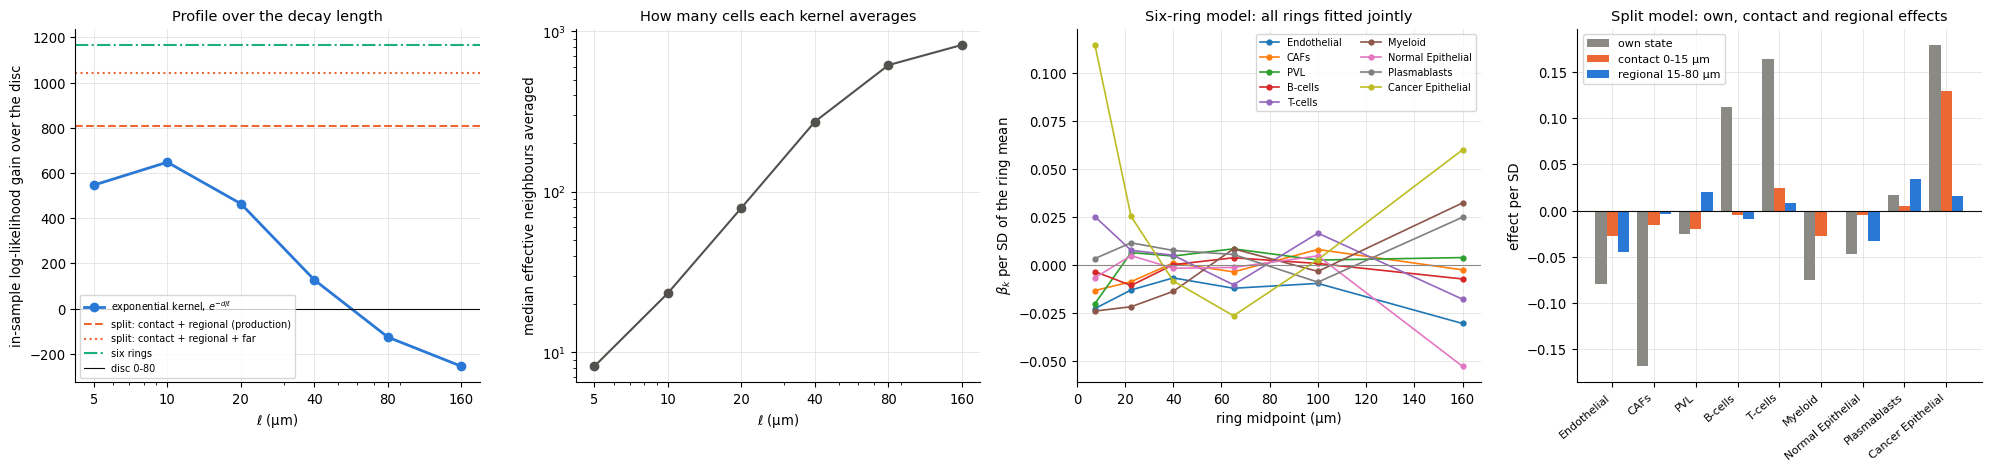

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
ax = axes[0]
ax.plot(ELLS, [nbr_tab.loc[m, "gain vs disc"] for m in exp_names], "o-", color=COL["real"], lw=2,
        label=r"exponential kernel, $e^{-d/\ell}$")
for m, ls, c in ((SPLIT, "--", COL["decoy"]), ("split: contact + regional + far", ":", COL["decoy"]),
                 ("six rings", "-.", COL["alt"])):
    ax.axhline(nbr_tab.loc[m, "gain vs disc"], ls=ls, color=c, lw=1.5,
               label=m + (" (production)" if m == SPLIT else ""))
ax.axhline(0, color=INK, lw=0.8, label="disc 0-80")
ax.set_xscale("log"); ax.set_xticks(ELLS); ax.set_xticklabels([f"{e:.0f}" for e in ELLS])
ax.set_xlabel(r"$\ell$ (µm)"); ax.set_ylabel("in-sample log-likelihood gain over the disc")
ax.set_title("Profile over the decay length"); ax.legend(fontsize=7)
ax = axes[1]
ax.plot(ELLS, [neff[e] for e in ELLS], "o-", color=COL["base"])
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(ELLS); ax.set_xticklabels([f"{e:.0f}" for e in ELLS])
ax.set_xlabel(r"$\ell$ (µm)"); ax.set_ylabel("median effective neighbours averaged"); ax.set_title("How many cells each kernel averages")
ax = axes[2]
for t in TYPES:
    ax.plot(mid, prof.loc[t], "o-", ms=3.5, lw=1.2, label=t)
ax.axhline(0, color=MUTED, lw=0.8); ax.set_xlabel("ring midpoint (µm)"); ax.set_ylabel(r"$\beta_k$ per SD of the ring mean")
ax.set_title("Six-ring model: all rings fitted jointly"); ax.legend(fontsize=7, ncol=2)
ax = axes[3]
xx = np.arange(len(TYPES)); w = 0.27
ax.bar(xx - w, split_tab["own (per SD)"], w, color=MUTED, label="own state")
ax.bar(xx, split_tab["contact"], w, color=COL["decoy"], label="contact 0-15 µm")
ax.bar(xx + w, split_tab["regional"], w, color=COL["real"], label="regional 15-80 µm")
ax.axhline(0, color=INK, lw=0.8); ax.set_xticks(xx); ax.set_xticklabels(TYPES, rotation=40, ha="right", fontsize=8)
ax.set_ylabel("effect per SD"); ax.set_title("Split model: own, contact and regional effects"); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "neighbourhood_models")

### Spatial cross-validation

Five folds of contiguous blocks, from the stored fold map. Each model is refit
on four folds, warm-started from its full-data fit, and scored on the fifth.
Five candidates are compared:
- no neighbour block;
- the disc;
- the two-block split (production);
- the best exponential kernel;
- the six-ring model.

The table gives the total held-out log-likelihood gain over the disc,
summed over all held-out cells, with the per-fold gains and a paired t across
folds. With five folds the t is a rough guide, so read it together with how
consistent the per-fold signs are.

In [30]:
fm = pd.read_parquet("outputs/division_classifier/folds.parquet")
assert (fm["cell_id"].astype(str).to_numpy() == df["cell_id"].astype(str).to_numpy()).all()
foldA = fm["fold"].to_numpy()[A]
print("fold sizes within the annulus set:", np.bincount(foldA).tolist())
CV = {"none": nbb.subset(D, A, nbr=np.zeros((len(A), 8))), DISC: nbb.subset(D, A, nbr=NBR[DISC]),
      SPLIT: nbb.subset(D, A, nbr=NBR[SPLIT]),
      BEST_EXP: nbb.subset(D, A, nbr=NBR[BEST_EXP]), "six rings": nbb.subset(D, A, nbr=NBR["six rings"])}
CVTAG = {"none": "none", **{k: TAG[k] for k in CV if k in TAG}}
cv_rows = []
for name, DD in CV.items():
    for fo_ in range(5):
        tr, te = np.flatnonzero(foldA != fo_), np.flatnonzero(foldA == fo_)
        g = nbb.cached(f"cv_{CVTAG[name]}_f{fo_}", lambda DD=DD, tr=tr, name=name: nbb.fit(
            nbb.subset(DD, tr), init=nbr_fit[name]["params"], se=False, **BASE, **PEN))
        ll = nbb.heldout_loglik(g, nbb.subset(DD, te))
        cv_rows.append({"model": name, "fold": fo_, "n_test": len(te), "heldout": ll.sum(),
                        "converged": g["info"]["converged"]})
cvd = pd.DataFrame(cv_rows)
piv = cvd.pivot(index="fold", columns="model", values="heldout")
gain = piv.sub(piv[DISC], axis=0)
cv_tab = pd.DataFrame({"total held-out gain vs disc": gain.sum(),
                       "per-fold gains": gain.apply(lambda s: " / ".join(f"{v:+.0f}" for v in s)),
                       "paired t": gain.mean() / (gain.std(ddof=1) / np.sqrt(5)),
                       "folds better than disc": (gain > 0).sum()})
cv_tab.loc[DISC, ["paired t"]] = np.nan
print(f"all CV fits converged: {cvd['converged'].all()}")
cvd.to_csv(OUT / "neighbourhood_cv.csv", index=False)
cv_tab.sort_values("total held-out gain vs disc")

fold sizes within the annulus set: [113782, 100914, 113359, 107475, 103829]


all CV fits converged: True


,total held-out gain vs disc,per-fold gains,paired t,folds better than disc
model,,,,
none,-1552.0699,-326 / -380 / -281 / -237 / -328,-12.8889,0
disc 0-80,0.0000,+0 / +0 / +0 / +0 / +0,NaN,0
"exp, ell = 10",641.4758,+111 / +137 / +134 / +136 / +124,26.4260,5
split: contact + regional,765.6270,+178 / +164 / +126 / +138 / +160,16.3766,5
six rings,916.5733,+236 / +165 / +155 / +143 / +217,9.9928,5


### Reading §5

**A short-range neighbourhood beats the uniform disc out of sample, on every
fold.**

| neighbourhood | parameters vs disc | held-out gain over the disc |
|---|---|---|
| none | −32 | −1,552 (worse on 5/5) |
| exponential kernel, $\ell$ = 10 µm (≈23 effective neighbours) | 0 | +641 (better on 5/5) |
| split: contact 0–15 + regional 15–80 µm (production) | +32 | +766 (5/5) |
| six rings | +160 | +917 (5/5) |

The MisTIC term takes up part of what the neighbourhood explains, mostly at
contact range (§4).

- **The kernel profile peaks at $\ell$ = 10 µm.** From 80 µm upward it is worse
  than the disc.
- **The six-ring fit shows two scales.** The contact ring dominates
  (‖β‖ 0.125 per SD), and 15–30 µm adds a little in the same direction (0.042,
  cosine 0.76). The 30–120 µm rings add little (0.02–0.03). The 120–200 µm ring
  returns (0.097): Cancer Epithelial +0.060, Normal Epithelial −0.053 and
  Myeloid +0.033.
- **In the split model,** the contact block carries Cancer Epithelial (0.129 per
  SD) and T-cells (0.025). The regional block carries Plasmablasts (0.034) and
  PVL (0.020). Endothelial (−0.045) and Normal Epithelial (−0.033) regions lower
  the rate.
- **A caution.** Contact effects correlate +0.72 with own-state effects across
  cell types (regional +0.38).
  Transcript spillover would do this, and so would proliferating cells
  clustering next to their own kind. With modelled spillover now in the mean,
  the second reading gains weight.

**Decision (user, 2026-10-07): the mixture's neighbour block is the
contact/regional split.** The MisTIC rerun confirms it.

## 6. Summary

| question | old notebook (SpaNorm scores) | this table, MisTIC technical terms | decision |
|---|---|---|---|
| technical terms | — | MisTIC gains 3,290 held out (5/5 folds) for one parameter; calibration unchanged; regional effects shrink, own-state effects sharpen | MisTIC |
| depth: offset or free | $\theta \approx 0.70$, free it | $\hat\theta$ = 1.097 ± 0.004; freeing it moves state effects by up to 5 SE; spline and per-type departures track proliferation | offset (θ = 1); the free-θ fit is reported beside it |
| dispersion: NB-c or NB-d | helps | NB-d: LR 327 on 8 df, +145 held out (4/5 folds), misfit −5%, PIT unchanged | NB-c in the baseline |
| does the oxygen source mark vessels? | AUROC 0.515 | 0.985 (source), 0.79 ($u$) | — |
| does $u$ explain division beyond state? | z ≈ +15, ~13× the decoy | $|\psi| \le 0.016$ per SD; leads its decoys only at $L_0$ = 50 µm | oxygen dropped |
| annulus, count-matched | decays more slowly than $\rho_\phi$ | decays with $\rho_\phi$; contact ring most informative | — |
| neighbourhood structure | — | split +766, $\ell$ = 10 µm kernel +641, six rings +917 held out | contact/regional split |

This run (2026-10-18) adds §1 (plain against MisTIC) and the head-to-head
comparison of NB-c and NB-d. No model in it has a cell-area term.
- **Technical terms.** MisTIC wins out of sample on every fold. It moves effects
  from the regional neighbourhood to the own state, as modelled spillover should.
- **Depth (reopened, then kept).** The free exponent is 1.097. Freeing it moves the
  state effects by up to 5 SE. In the mixture, freeing it ($\hat\theta$ = 1.119)
  leaves the neighbourhood effects within their intervals but raises the cycling
  fraction from 0.098 to 0.133. The offset stays in production (user, 2026-10-13),
  and the free fit is reported beside it.
- **Dispersion.** NB-d is a little better held out (+145 on 8 parameters); NB-c
  remains the baseline here.
- **Oxygen** is dropped, and the **neighbourhood** is the contact/regional split.

What changed in the penalty and its selection, and why, is set out in the
[specification decisions document](https://claude.ai/code/artifact/70c686de-ba2d-4b2d-8d17-f29b5e2c2077).